### Melt rate for idealised ice shelf cavities

In [141]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime
plt.rcParams['font.family'] = 'serif'

plt.rcParams['mathtext.fontset'] = 'cm'

def plot_m_vs_y(H, y_values, beta, D, T2, W, ax=None):
    """
    Takes a function H(y) and plots m(y) = dH/dy against y.
    
    Parameters:
    H: a function that takes y as input
    y_values: array of y values to evaluate
    Parameters:
    H: slope of the ice base
    y_values: array of y values
    calculation_func: function to convert H to melt rate in m/s
    T2: temperature of the lower layer
    D: depth of the sea floor
    beta: ratio of h1 to h2

    """
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    Lf = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974 
    alpha = 0.094

    g_prime = g*(rho_2-rho_1)/rho_2
    k = alpha*C_p*(T2-Tf)*g_prime*rho_2/(rho_i*Lf*f*(beta+1))
    # Calculate H(y)
    H_values = H(y_values)

    # Calculate derivative of H at each y value
    H_prime = np.gradient(H_values, y_values)
    m_values = -H_prime*(D-H_values)*k/W 
    m_values_year = m_values*(60*60*24*365)

    print(f"k = {k}")
    print(f"H_prime max = {np.max(H_prime)}")
    print(f"(D-H) max = {np.max(D-H_values)}")
    print(f"W = {W}")
    print(f"m_values max (m/s) = {np.max(m_values)}")
    print(f"m_values max (m/yr) = {np.max(m_values_year)}")


    if ax is None:
        plt.figure(figsize=(8, 6))
        ax = plt.gca()
    
    ax.plot(y_values/1000, m_values_year)
    ax.set_xlabel('Distance from grounding line (km)')
    ax.set_ylabel('Melt rate (m/yr)')
    ax.set_title(f"Melt rate for a cavity")
    ax.grid(True)

In [142]:
def linear_H(y):
    a= 0.005
    D = 600
    return D - a*y

k = 0.047127785345350566
H_prime max = -0.004999999999999949
(D-H) max = 500.0
W = 50000
m_values max (m/s) = 2.3563892672675236e-06
m_values max (m/yr) = 74.31109193254862


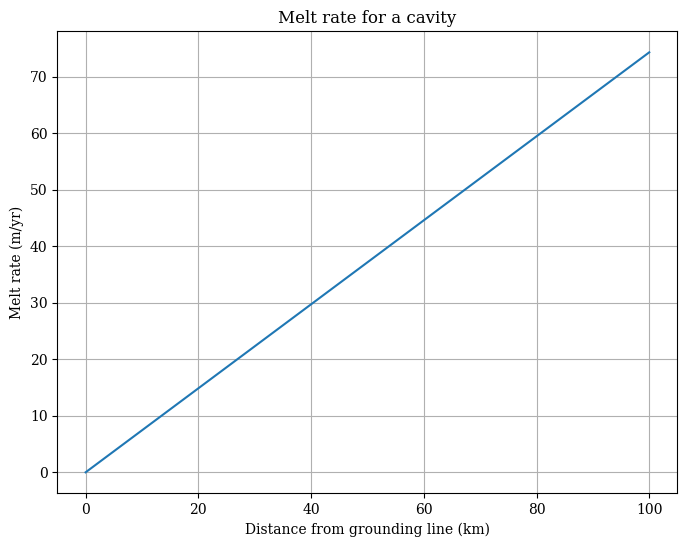

In [143]:
y_vals = np.linspace(0,100000,100)
plot_m_vs_y(linear_H, y_vals, 2.5, 600, 5, 50000)

In [144]:
def exp_H(y):
    H_gl = 600
    H_front = 150
    L = 15000
    return H_front + (H_gl - H_front) * np.exp(-y / (L))

k = 0.016392273163600195
H_prime max = -3.9493850083725e-05
(D-H) max = 449.4273147893971
W = 50000
m_values max (m/s) = 1.1068744890745627e-06
m_values max (m/yr) = 34.90639388745541


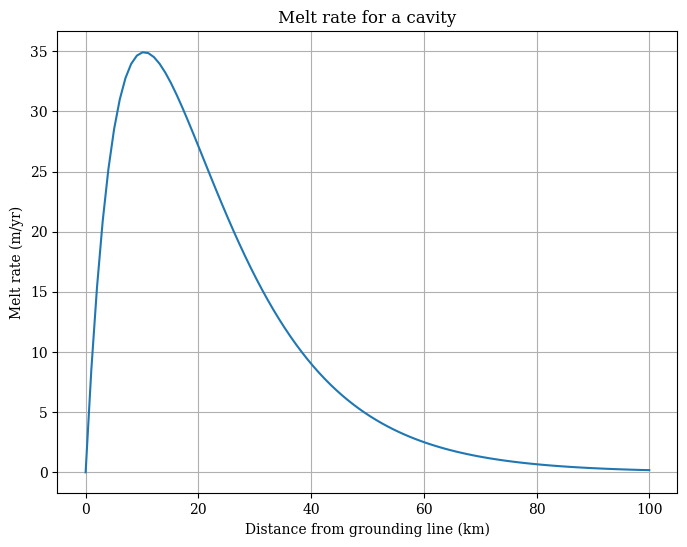

In [145]:
# Melt rate for cavity with exponential slope
y_vals = np.linspace(0,100000,100)
plot_m_vs_y(exp_H, y_vals, 2.5, 600, 0.5, 50000)

In [146]:
from scipy.interpolate import UnivariateSpline

def plot_m_vs_y_smooth(H, y_values, beta, D, T2, W):
    
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34*10**5
    f = 10**(-4)
    alpha = 0.094
    C_p = 3974 

    g_prime = g*(rho_2-rho_1)/rho_2
    k = alpha*C_p*(T2-Tf)*g_prime*rho_2/(rho_i*Lf*f*(beta+1))
   
    H_values = H(y_values)
    
    # Fit a spline to smooth the function
    spl = UnivariateSpline(y_values, H_values, s=1e10)  
    H_smooth = spl(y_values)
    H_prime = spl.derivative()(y_values)  
    print(np.max(np.abs(H_prime)))

    m_values = -H_prime * (D - H_smooth) * k / W
    m_values_year = m_values * (60*60*24*365)
    print("g_prime =", g_prime)

    plt.figure(figsize=(8, 6))
    plt.plot(y_values/1000, m_values_year)
    plt.xlabel('Distance from grounding line (km)')
    plt.ylabel('Melt rate (m/yr)')
    plt.title(f"Melt rate for a cavity")
    plt.grid(True)
    plt.show()

In [147]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

def plot_M_vs_y(H, y_values, beta, D, T2, W):
    """
    Parameters:
    H: a function that takes y as input
    y_values: array of y values to evaluate
    Parameters:
    H: slope of the ice base
    y_values: array of y values
    calculation_func: function to convert H to melt rate in m/s
    T2: temperature of the lower layer
    D: depth of the sea floor
    beta: ratio of h1 to h2

    """
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    L = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974
    alpha = 0.094
    k = alpha*(T2-Tf)*g*(rho_2-rho_1)*C_p/(rho_i*L*f*(beta+1))
    # Calculate H(y)
    H_values = H(y_values)

    m_values = (H_values*(D-0.5*H_values)-0.5*D**2)*k # in m^3/s
    m_values_year = -m_values*(60*60*24*365)
    m_values_gton = m_values_year*917/10**12
    plt.figure(figsize=(8, 6))
    plt.plot(y_values/1000, m_values_gton)
    plt.xlabel('Distance from grounding line (km)')
    plt.ylabel('Melt rate (Gt/yr)')
    plt.title(f"Integrated melt rate for a cavity")
    plt.grid(True)
    plt.show()

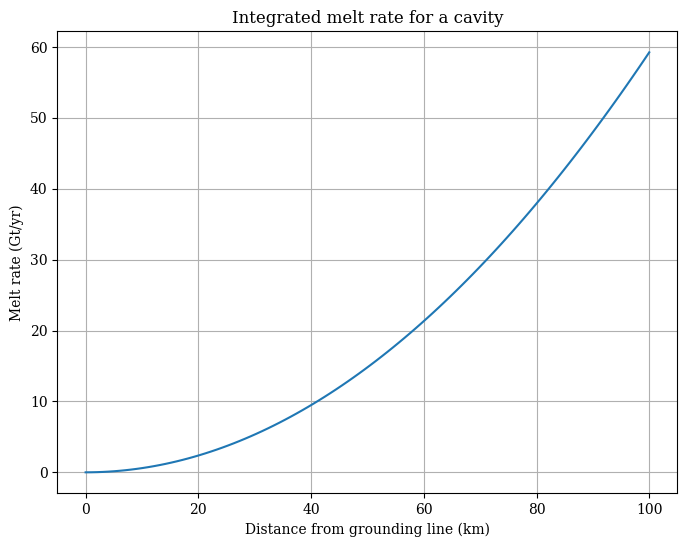

In [148]:
plot_M_vs_y(linear_H, y_vals, 2.5, 600, 0.5, 50000)

### Now for some realistic ice shelves: Thwaites

DOI: 10.1126/sciadv.abd7254
D to be the depth of H at the grounding line and constant
For the varying D: 

In [149]:
def thwaites_H(y):
    y_km = y / 1000
    y_km = np.atleast_1d(y_km)
    H_vals = np.zeros_like(y_km, dtype=float)
    
    H_gl = 900
    H_front = 300
    
    H_vals = H_gl - (H_gl - H_front) * (1 - np.exp(-y_km / 50))
    
    return H_vals if len(H_vals) > 1 else H_vals[0]

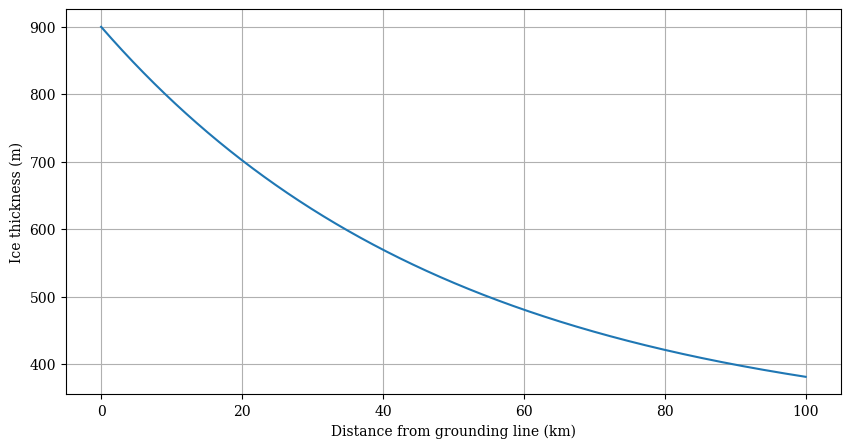

In [150]:
y_test = np.linspace(0, 100000, 1000)
H_test = thwaites_H(y_test)

plt.figure(figsize=(10, 5))
plt.plot(y_test/1000, H_test)
plt.xlabel('Distance from grounding line (km)')
plt.ylabel('Ice thickness (m)')
plt.grid(True)
plt.show()

0.011485796753094501
g_prime = 0.0019070785696915066


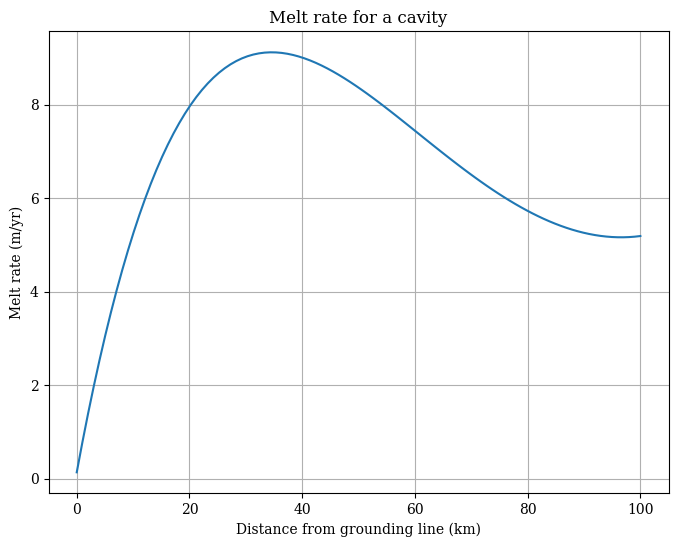

In [151]:
plot_m_vs_y_smooth(thwaites_H, y_vals, 2.5, 900, 1, 125000)

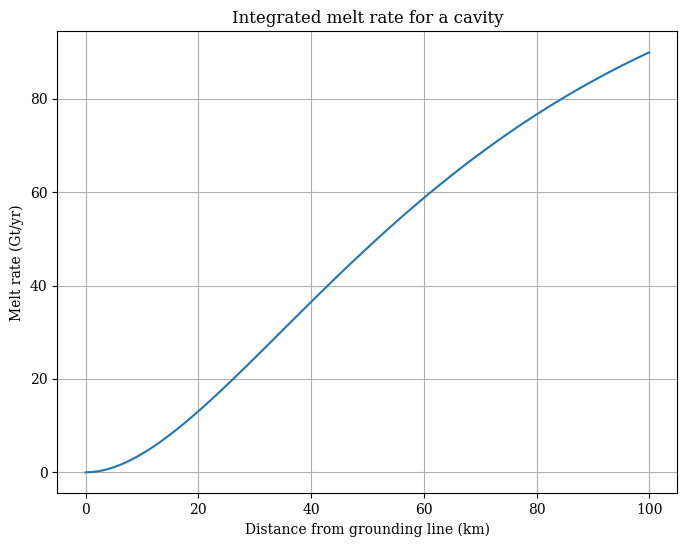

In [152]:
W=125000
plot_M_vs_y(thwaites_H, y_vals, 2, 900, 1, W)

In [153]:
# cumulative melt for linear depth and exponential slope
def M_linD_expH(y_vals, H_gl,H_f, D_f, L, l, beta, T2):
    delta_H = H_gl-H_f
    delta_D = -H_gl+D_f
    
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    L = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974
    alpha = 0.094
    k = alpha*(T2-Tf)*g*(rho_2-rho_1)*C_p/(rho_i*L*f*(beta+1))

    int = np.exp(-y_vals/l)*(delta_H**2+delta_H*delta_D*(-y_vals/L+l/L))-((delta_H**2)/2)*np.exp(-2*y_vals/l)-(delta_H**2)/2-l/L*delta_H*delta_D
    M = -k*int*60*60*24*365*917/10**12

    plt.grid()
    plt.title("Cumulative melt for Thwaites glacier, using a linear sea bed and exponential ice thickness")
    plt.xlabel("y (km)")
    plt.ylabel("M(y) (Gt/yr)")
    plt.plot(y_vals/1000, M)
    
    

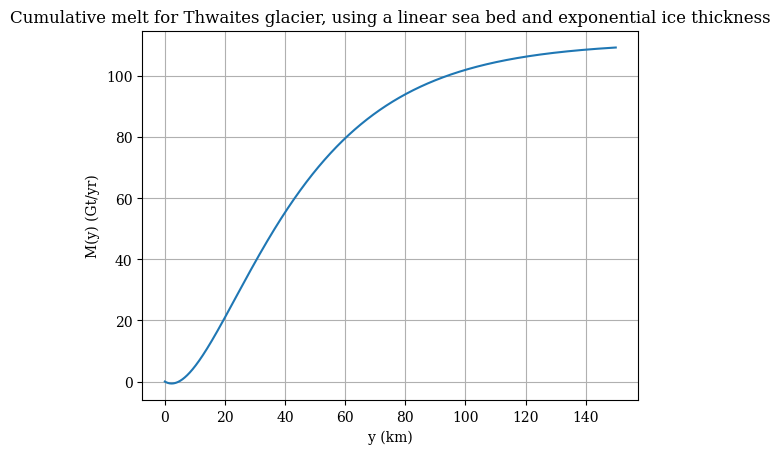

In [154]:
y_vals = np.linspace(0, 150000, 100000)
H_gl = 900
D_f = 650
H_f = 300
L = 100000
l = 30000
beta = 2
T2 = 1
M_linD_expH(y_vals, H_gl,H_f, D_f, L, l, beta, T2)

In [155]:
# cumulative melt for linear depth and exponential slope
def m_linD_expH(y_vals, H_gl,H_f, D_f, L, l, beta, T2,W, ax=None):
    H = H_f +(H_gl-H_f)*np.exp(-y_vals/l)
    H_prime = -1/l*(H_gl-H_f)*np.exp(-y_vals/l)
    D = H_gl + (D_f-H_gl)*y_vals/L
    
     
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    L = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974
    alpha = 0.094
    k = alpha*(T2-Tf)*g*(rho_2-rho_1)*C_p/(rho_i*L*f*(beta+1))
    m = -H_prime*(D-H)*k/W*60*60*24*365


    if ax is None:
        ax = plt.gca()
    
    ax.plot(y_vals/1000, m,  linewidth=2)
     # Find the maximum melt and its location
    max_idx = np.argmax(m)
    max_y = y_vals[max_idx] / 1000  # Convert to km
    max_m = m[max_idx]
    
    # Add scatter point at maximum
    ax.scatter(max_y, max_m, s=30, zorder=5, color='red')
    
    # Add dotted lines to axes
    ax.axvline(max_y, color='red', linestyle=':', alpha=0.6)
    ax.axhline(max_m, color='red', linestyle=':', alpha=0.6)

    
    ax.text(max_y, max_m, f'  {max_y:.2e} km', fontsize=9, va='center')
    
    ax.set_xlabel('y (km)', fontsize=12)
    ax.set_ylabel('M(y) (Gt/yr)', fontsize=12)
    ax.set_title('Cumulative melt for Thwaites glacier (linear sea bed, exponential ice thickness)')
    ax.grid(True, alpha=0.3)
    

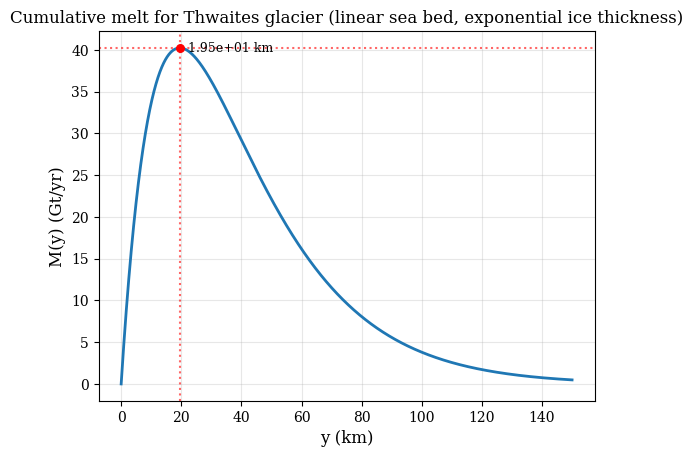

In [156]:
y_vals = np.linspace(0, 150000, 100000)
H_gl = 900
D_f = 650
H_f = 300
L = 100000
l = 30000
beta = 2
T2 = 1
W = 45000
m_linD_expH(y_vals, H_gl,H_f, D_f, L, l, beta, T2, W)

### Melt rate approximated for various A=H*L

In [157]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def average_melt(y_max, W, area, T2, D,  H_f, l, beta):
    """Calculate average melt rate in m/year"""
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    L = 3.34e5
    f = 1e-4
    alpha = 0.094
    
    C_p = 3993 
    k = alpha*(T2-Tf)*g*(rho_2-rho_1)*C_p/(rho_i*L*f*(beta+1))
    H_max = D-(D-H_f)*(1-np.exp(-y_max/l))
    M_max = (H_max * (D - 0.5 * H_max) - 0.5 * D**2) * k  # m/s
    M_max_year = -M_max * (60 * 60 * 24 * 365)*917/10**12  # Gt/year
    average_M = M_max_year   # average over shelf area
    m_avg = average_M*10**12/917/area/10**6
    return average_M, m_avg

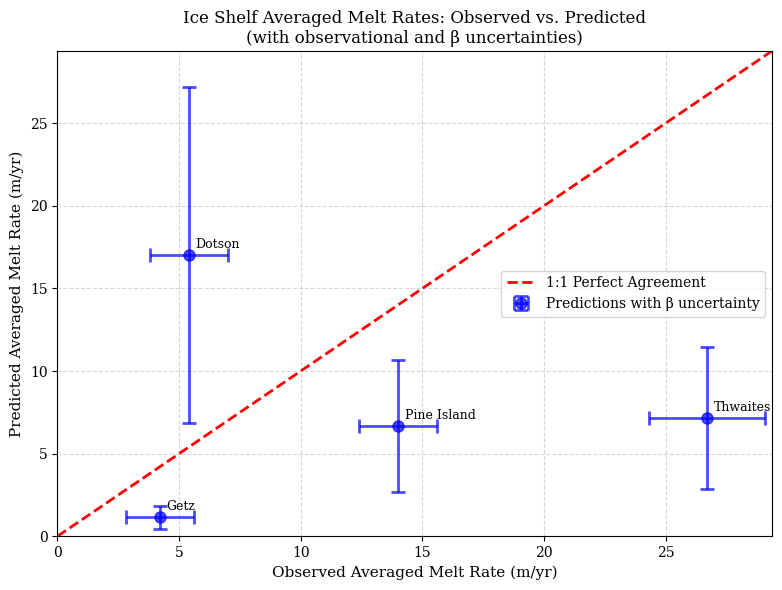

          name  observed_M  predicted_M  observed_m  predicted_m
0     Thwaites        69.5    22.046681        26.7     7.172489
1  Pine Island        60.2    36.364566        14.0     6.664877
2         Getz        61.2    34.083775         4.2     1.157401
3       Dotson        12.5    88.345896         5.4    17.030636

β = 2.862 ± 1.8051


In [158]:

# using observed melt from SI from Interannual variations in meltwater input to the southern Ocean from Antarctic ice shelves

observed_shelves = pd.DataFrame({
    'name': ['Thwaites', 'Pine Island', 'Getz', 'Dotson'],
    'W': [45000, 50000, 65000, 50000],  # width in m
    'y_max': [83000, 50000, 70000, 40000],  # extent in m
    'H_f': [265, 425, 325, 250],  # depth at ice front in m
    'D': [558, 1100, 850, 950],  # sea floor depth in m
    'T2': [1.044, 0.9, 1, 0.85], #annual CDW temperatures
    'observed_M': [81.1-11.6, 76.0-15.8, 122.6-61.4, 26.1-13.6],  # observed total melt in Gt/yr
    'observed_M_err': [7.4, 8.7, 40.9, 8.5],
    'observed_m': [26.7, 14.0, 4.2, 5.4],
    'observed_m_err': [2.4, 1.6, 1.4, 1.6],
    'decay_scale': [19800, 60400, 60000, 20800],
    'area': [3352, 5950, 32114, 5657] # in km
})

# Model parameters (fixed)
beta = 2.8620  # proportion of water height in the upper layer
beta_err = 1.8051
# Lists to store results
predicted_M = []
predicted_M_lower = []
predicted_M_upper = []
predicted_m = []
predicted_m_lower = []
predicted_m_upper = []

# Loop through each row in the dataframe
for index, row in observed_shelves.iterrows():
    M_total, m_avg = average_melt(
        row['y_max'], 
        row['W'], 
        row['area'],
        row['T2'], 
        row['D'],  
        row['H_f'], 
        row['decay_scale'],
        beta
    )
    predicted_M.append(M_total)
    predicted_m.append(m_avg)

    # Lower bound (beta - beta_err)
    M_lower, m_lower = average_melt(
        row['y_max'], 
        row['W'], 
        row['area'],
        row['T2'], 
        row['D'],  
        row['H_f'], 
        row['decay_scale'],
        beta - beta_err
    )
    predicted_M_lower.append(M_lower)
    predicted_m_lower.append(m_lower)

    # Upper bound (beta + beta_err)
    M_upper, m_upper = average_melt(
        row['y_max'], 
        row['W'], 
        row['area'],
        row['T2'], 
        row['D'],  
        row['H_f'], 
        row['decay_scale'],
        beta + beta_err
    )
    predicted_M_upper.append(M_upper)
    predicted_m_upper.append(m_upper)

# Add to dataframe
observed_shelves['predicted_M'] = predicted_M
observed_shelves['predicted_M_lower'] = predicted_M_lower
observed_shelves['predicted_M_upper'] = predicted_M_upper

observed_shelves['predicted_m'] = predicted_m
observed_shelves['predicted_m_lower'] = predicted_m_lower
observed_shelves['predicted_m_upper'] = predicted_m_upper





# --- Plotting Averaged Melt Rate (m) ---
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate asymmetric error bars for predictions
pred_m_err = np.abs(np.array(predicted_m_upper) - np.array(predicted_m_lower)) / 2

# Error bars
ax.errorbar(
    observed_shelves['observed_m'], 
    observed_shelves['predicted_m'],
    xerr=observed_shelves['observed_m_err'],  # horizontal error bars
    yerr=pred_m_err,  # vertical error bars
    fmt='o', 
    color='blue', 
    markersize=8,
    capsize=5,
    capthick=2,
    elinewidth=2,
    alpha=0.7,
    label='Predictions with β uncertainty'
)

# Add labels
for i, txt in enumerate(observed_shelves['name']):
    ax.annotate(txt, (observed_shelves['observed_m'][i], observed_shelves['predicted_m'][i]), 
                 xytext=(5, 5), textcoords='offset points', fontsize=9)

# 1:1 line
limit = max(max(observed_shelves['observed_m']), max(observed_shelves['predicted_m'])) * 1.1
ax.plot([0, limit], [0, limit], 'r--', label='1:1 Perfect Agreement', linewidth=2)

ax.set_xlabel('Observed Averaged Melt Rate (m/yr)', fontsize=11)
ax.set_ylabel('Predicted Averaged Melt Rate (m/yr)', fontsize=11)
ax.set_title('Ice Shelf Averaged Melt Rates: Observed vs. Predicted\n(with observational and β uncertainties)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
plt.tight_layout()
plt.show()

# Print comparison
print(observed_shelves[['name', 'observed_M', 'predicted_M', 'observed_m', 'predicted_m']])
print(f"\nβ = {beta} ± {beta_err}")

In [159]:
# Back-calculate beta from observations
cavity_heights = {
    'Thwaites': 478,   # max cavity height from results
    'Dotson':   498,
    'Getz':     191,
}

cdw_observed = {
    'Thwaites': 150,   # literature value ~150m (WOA unreliable here)
    'Dotson':   250,   # from WOA results
    'Getz':     150,   # from WOA results
}

print(f"{'Shelf':<12} {'Cavity H':>10} {'CDW obs (m)':>12} {'beta':>8} {'CDW_calc (m)':>13}")
print("─" * 55)
for name in cavity_heights:
    H_cav  = cavity_heights[name]
    H_cdw  = cdw_observed[name]
    beta   = (H_cav / H_cdw) - 1
    H_check = H_cav / (beta + 1)
    print(f"{name:<12} {H_cav:>10} {H_cdw:>12} {beta:>8.2f} {H_check:>13.0f}")

Shelf          Cavity H  CDW obs (m)     beta  CDW_calc (m)
───────────────────────────────────────────────────────
Thwaites            478          150     2.19           150
Dotson              498          250     0.99           250
Getz                191          150     0.27           150


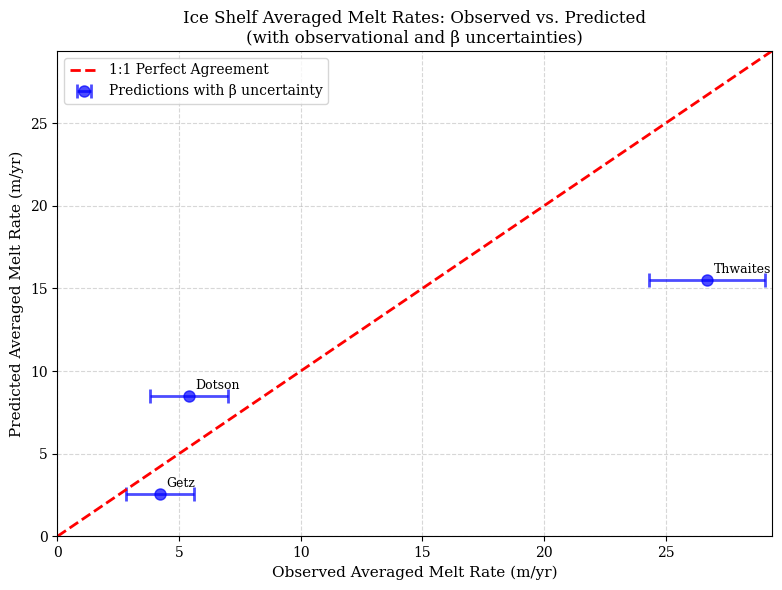

       name  observed_M  predicted_M  observed_m  predicted_m
0  Thwaites        69.5    47.757926        26.7    15.537177
1      Getz        61.2    75.857973         4.2     2.575950
2    Dotson        12.5    44.138745         5.4     8.508725


In [160]:
# using the bedmap fit to exponential curves
# using observed melt from SI from Interannual variations in meltwater input to the southern Ocean from Antarctic ice shelves

observed_shelves = pd.DataFrame({
    'name': ['Thwaites',  'Getz', 'Dotson'],
    'W': [45000, 65000, 50000],  # width in m
    'y_max': [92000,  283000, 94000],  # extent in m
    'H_f': [265,  101.9, 308.4],  # depth at ice front in m
    'D': [656,  622, 615],  # sea floor depth in m
    'T2': [1.044,  1, 0.85], #annual CDW temperatures
    'observed_M': [81.1-11.6,  122.6-61.4, 26.1-13.6],  # observed total melt in Gt/yr
    'observed_M_err': [7.4,  40.9, 8.5],
    'observed_m': [26.7, 4.2, 5.4],
    'observed_m_err': [2.4,  1.4, 1.6],
    'decay_scale': [21100,  313400, 20800],
    'area': [3352,  32114, 5657], # in km,
    'beta' : [2.19, 0.27, 0.99]
})


# Lists to store results
predicted_M = []
predicted_M_lower = []
predicted_M_upper = []
predicted_m = []
predicted_m_lower = []
predicted_m_upper = []

# Loop through each row in the dataframe
for index, row in observed_shelves.iterrows():
    M_total, m_avg = average_melt(
        row['y_max'], 
        row['W'], 
        row['area'],
        row['T2'], 
        row['D'],  
        row['H_f'], 
        row['decay_scale'],
        row['beta']
    )
    predicted_M.append(M_total)
    predicted_m.append(m_avg)

    # Lower bound (beta - beta_err)
    M_lower, m_lower = average_melt(
        row['y_max'], 
        row['W'], 
        row['area'],
        row['T2'], 
        row['D'],  
        row['H_f'], 
        row['decay_scale'],
        beta - beta_err
    )
    predicted_M_lower.append(M_lower)
    predicted_m_lower.append(m_lower)

    # Upper bound (beta + beta_err)
    M_upper, m_upper = average_melt(
        row['y_max'], 
        row['W'], 
        row['area'],
        row['T2'], 
        row['D'],  
        row['H_f'], 
        row['decay_scale'],
        beta + beta_err
    )
    predicted_M_upper.append(M_upper)
    predicted_m_upper.append(m_upper)

# Add to dataframe
observed_shelves['predicted_M'] = predicted_M
observed_shelves['predicted_M_lower'] = predicted_M_lower
observed_shelves['predicted_M_upper'] = predicted_M_upper

observed_shelves['predicted_m'] = predicted_m
observed_shelves['predicted_m_lower'] = predicted_m_lower
observed_shelves['predicted_m_upper'] = predicted_m_upper





# --- Plotting Averaged Melt Rate (m) ---
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate asymmetric error bars for predictions
pred_m_err = np.abs(np.array(predicted_m_upper) - np.array(predicted_m_lower)) / 2

# Error bars
ax.errorbar(
    observed_shelves['observed_m'], 
    observed_shelves['predicted_m'],
    xerr=observed_shelves['observed_m_err'],  # horizontal error bars
    
    fmt='o', 
    color='blue', 
    markersize=8,
    capsize=5,
    capthick=2,
    elinewidth=2,
    alpha=0.7,
    label='Predictions with β uncertainty'
)

# Add labels
for i, txt in enumerate(observed_shelves['name']):
    ax.annotate(txt, (observed_shelves['observed_m'][i], observed_shelves['predicted_m'][i]), 
                 xytext=(5, 5), textcoords='offset points', fontsize=9)

# 1:1 line
limit = max(max(observed_shelves['observed_m']), max(observed_shelves['predicted_m'])) * 1.1
ax.plot([0, limit], [0, limit], 'r--', label='1:1 Perfect Agreement', linewidth=2)

ax.set_xlabel('Observed Averaged Melt Rate (m/yr)', fontsize=11)
ax.set_ylabel('Predicted Averaged Melt Rate (m/yr)', fontsize=11)
ax.set_title('Ice Shelf Averaged Melt Rates: Observed vs. Predicted\n(with observational and β uncertainties)', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
plt.tight_layout()
plt.show()

# Print comparison
print(observed_shelves[['name', 'observed_M', 'predicted_M', 'observed_m', 'predicted_m']])


In [161]:
import numpy as np
import pandas as pd
from scipy import stats



# Also show for averaged melt rate (m)
print("\n" + "=" * 80)
print("AVERAGED MELT RATE (m) - FOR REFERENCE")
print("=" * 80)

obs_m_all = observed_shelves['observed_m'].values
pred_m_all = observed_shelves['predicted_m'].values

r_m_all, p_m_all = stats.pearsonr(obs_m_all, pred_m_all)
r2_m_all = r_m_all ** 2
rmse_m_all = np.sqrt(np.mean((pred_m_all - obs_m_all) ** 2))


print(f"\nWith all shelves (n=4):")
print(f"  r = {r_m_all:.4f}, R² = {r2_m_all:.4f}, RMSE = {rmse_m_all:.2f} m/yr")




AVERAGED MELT RATE (m) - FOR REFERENCE

With all shelves (n=4):
  r = 0.9100, R² = 0.8282, RMSE = 6.76 m/yr


### Comparing to F&S plot

In [162]:
def depth(y_gl, d_far, L, y_values):
    D = y_gl +(d_far-y_gl)*y_values/L
    return D


In [163]:
def m_average( y_gl, y_f, d_far, W, L, beta):
    H_prime = (y_f-y_gl)/L
    D_prime = (d_far-y_gl)/250000

    Tf = -1.8
    T2 = 0.5
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.094

    
    k = alpha*C_p*(T2 - Tf) * g * (rho_2 - rho_1) / (rho_i * Lf * f)/W/(beta+1)

    m_avg = -k*L*(H_prime)*(D_prime-H_prime)*60*60*24*364 # in m/yr
    return m_avg

In [164]:
def m_average_f_s( s_ice, s_bed, gprime, L, T2, W, H_CDW,  D_f):
    H_prime = s_ice
    D_prime = s_bed

    Tf = -1.8
    
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.094
    H_f = 250
    beta = (H_f-D_f)/H_CDW -1
    
    k = alpha*C_p*(T2 - Tf) * gprime / (Lf * f)/W/(beta+1)

    m_avg = -k*L*(H_prime)*(D_prime-H_prime)*60*60*24*364 # in m/yr
    return m_avg

In [165]:
from scipy import stats

def add_stats(ax, x, y):
    slope_origin = np.sum(x*y) / np.sum(x**2)
    _, _, r, _, _ = stats.linregress(x, y)
    rmse = np.sqrt(np.mean((y - x)**2))
    bias = np.mean(y - x)
    textstr = f'R²={r**2:.3f}\nRMSE={rmse:.2f} m/yr\nBias={bias:.2f} m/yr\nSlope={slope_origin:.3f}'
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

Calculated beta values: [0.48118538 0.47453278 0.15749796 1.38493667 2.60210868 1.79116155
 0.98551853 0.928709   1.14261408 0.65593667 0.81138923 1.53433451
 1.30752268 1.19725961 0.84288768 0.57211086 1.0465155  0.27504843
 0.51719165 0.53908476 0.87441466 0.74581949 0.66548186 0.86328603
 0.56235409]
Optimal alpha (f_and_s): 0.1483
Optimal alpha (soane):   0.5761


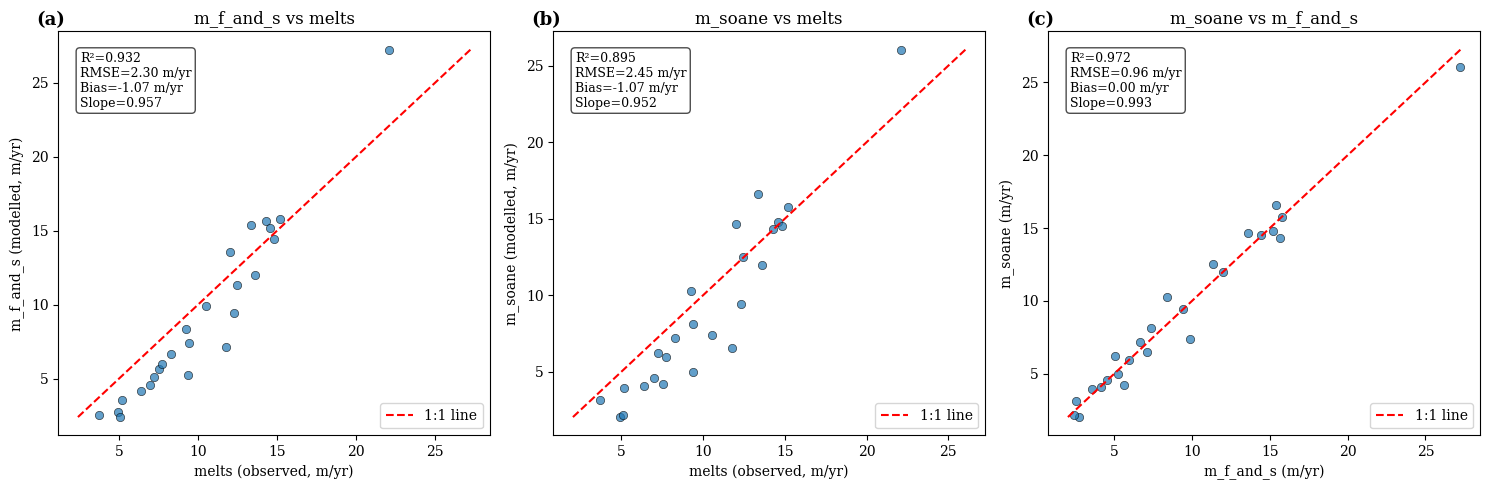

In [166]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('params_fix_w.csv')
df = df.dropna()  


rho_2 = 1027.75
rho_i = 917
Lf    = 3.34e5
f     = 1e-4
C_p   = 3974


hub    = df['hub'].values
deltaT    = df['Tcdw'].values      
gprime = df['gprime'].values
s_ice  = df['s_ice'].values
s_bed  = df['s_bed'].values
melts  = df['melts'].values * 365*24*60*60
HCDW   = df['deltaH'].values
L = df['L'].values*1000
W0 = 100000
W = 150000

H_prime = -s_ice
D_prime = -s_bed


beta = np.maximum((np.abs(hub)-200+s_bed*(250000-L))/(HCDW) -1, 0)
#beta=0
print(f"Calculated beta values: {beta}")

# compute models without alpha
k_no_alpha    = C_p * deltaT * gprime * rho_2 / (rho_i * Lf * f) 
m_f_and_s_no_alpha = -k_no_alpha * H_prime * HCDW * 60*60*24*365/W0
m_soane_no_alpha   = -k_no_alpha * L * H_prime * (D_prime - H_prime) * 60*60*24*365/2/ (beta + 1)/W

# find optimal alpha for each via OLS through origin
alpha_fs    = np.sum(melts * m_f_and_s_no_alpha) / np.sum(m_f_and_s_no_alpha**2)
alpha_soane = np.sum(melts * m_soane_no_alpha)   / np.sum(m_soane_no_alpha**2)
print(f'Optimal alpha (f_and_s): {alpha_fs:.4f}')
print(f'Optimal alpha (soane):   {alpha_soane:.4f}')

# compute final predictions with optimal alphas
m_f_and_s = alpha_fs    * m_f_and_s_no_alpha
m_soane   = alpha_soane * m_soane_no_alpha
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

panels = [
    (melts, m_f_and_s, 'melts (observed, m/yr)', 'm_f_and_s (modelled, m/yr)', 'm_f_and_s vs melts'),
    (melts, m_soane,  'melts (observed, m/yr)', 'm_soane (modelled, m/yr)',  'm_soane vs melts'),
    (m_f_and_s, m_soane, 'm_f_and_s (m/yr)',           'm_soane (m/yr)',            'm_soane vs m_f_and_s'),
]


for ax, (x, y, xlabel, ylabel, title) in zip(axes, panels):
    ax.scatter(x, y, alpha=0.7, edgecolors='k', linewidths=0.5)
    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lims, lims, 'r--', label='1:1 line')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    add_stats(ax, x, y)  

for i, ax in enumerate(axes):
    ax.text(-0.05, 1.05, f'({chr(97+i)})', transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top')

plt.tight_layout()
plt.savefig('combined_melt_plots_var_beta.png', dpi=150)
plt.show()

Calculated beta values: [0.48118538 0.47453278 0.15749796 1.38493667 2.60210868 1.79116155
 0.98551853 0.928709   1.14261408 0.65593667 0.81138923 1.53433451
 1.30752268 1.19725961 0.84288768 0.57211086 1.0465155  0.27504843
 0.51719165 0.53908476 0.87441466 0.74581949 0.66548186 0.86328603
 0.56235409]

--- OLS through origin ---
  alpha (f_and_s): 0.1483
  alpha (soane):   0.5761

--- Bias minimisation ---
  alpha (f_and_s): 0.1654
  alpha (soane):   0.6425


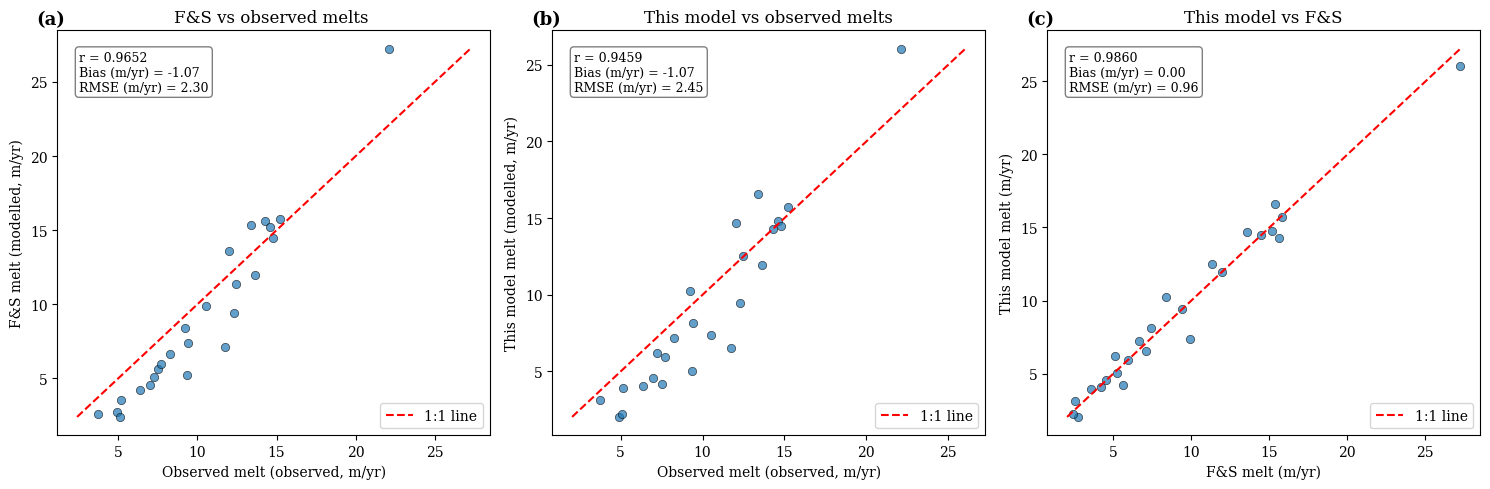

In [167]:

df = pd.read_csv('params_fix_w.csv')
df = df.dropna()

rho_2 = 1027.75
rho_i = 917
Lf    = 3.34e5
f     = 1e-4
C_p   = 3974
W0     = 100000
W = 150000

hub    = df['hub'].values
deltaT = df['Tcdw'].values
gprime = df['gprime'].values
s_ice  = df['s_ice'].values
s_bed  = df['s_bed'].values
melts  = df['melts'].values * 365 * 24 * 60 * 60
HCDW   = df['deltaH'].values
L      = df['L'].values * 1000

H_prime = -s_ice
D_prime = -s_bed
beta    = np.maximum((np.abs(hub) - 200 + s_bed * (250000 - L)) / HCDW - 1, 0)
print(f"Calculated beta values: {beta}")

k_no_alpha = C_p * deltaT * gprime * rho_2 / (rho_i * Lf * f) 

m_f_and_s_no_alpha = -k_no_alpha * H_prime * HCDW * 60 * 60 * 24 * 365/W0
m_soane_no_alpha   = (-k_no_alpha * L * H_prime * (D_prime - H_prime)
                      * 60 * 60 * 24 * 365 / 2 / (beta + 1))/W

def alpha_ols(obs, model):
    """OLS through origin — minimises sum of squared residuals."""
    return np.sum(obs * model) / np.sum(model**2)

def alpha_bias(obs, model):
    """Bias minimisation — forces mean prediction to equal mean observation."""
    return np.mean(obs) / np.mean(model)


alpha_fs_ols    = alpha_ols(melts,  m_f_and_s_no_alpha)
alpha_soane_ols = alpha_ols(melts,  m_soane_no_alpha)
alpha_fs_bias   = alpha_bias(melts, m_f_and_s_no_alpha)
alpha_soane_bias= alpha_bias(melts, m_soane_no_alpha)

print(f"\n--- OLS through origin ---")
print(f"  alpha (f_and_s): {alpha_fs_ols:.4f}")
print(f"  alpha (soane):   {alpha_soane_ols:.4f}")
print(f"\n--- Bias minimisation ---")
print(f"  alpha (f_and_s): {alpha_fs_bias:.4f}")
print(f"  alpha (soane):   {alpha_soane_bias:.4f}")

m_f_and_s = alpha_fs_ols    * m_f_and_s_no_alpha
m_soane   = alpha_soane_ols * m_soane_no_alpha


def add_stats(ax, x, y):
    r    = np.corrcoef(x, y)[0, 1]
    bias = np.mean(y - x)
    rmse = np.sqrt(np.mean((y - x)**2))
    ax.text(
        0.05, 0.95,
        f"r = {r:.4f}\nBias (m/yr) = {bias:.2f}\nRMSE (m/yr) = {rmse:.2f}",
        transform=ax.transAxes, va='top', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.5)
    )


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

panels = [
    (melts,     m_f_and_s, 'Observed melt (observed, m/yr)',  'F&S melt (modelled, m/yr)', 'F&S vs observed melts '),
    (melts,     m_soane,   'Observed melt (observed, m/yr)',  'This model melt (modelled, m/yr)',   'This model vs observed melts'),
    (m_f_and_s, m_soane,   'F&S melt (m/yr)',        'This model melt (m/yr)',             'This model vs F&S'),
]

for ax, (x, y, xlabel, ylabel, title) in zip(axes, panels):
    ax.scatter(x, y, alpha=0.7, edgecolors='k', linewidths=0.5)
    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lims, lims, 'r--', label='1:1 line')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    add_stats(ax, x, y)

for i, ax in enumerate(axes):
    ax.text(-0.05, 1.05, f'({chr(97 + i)})',
            transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')

plt.tight_layout()
plt.savefig('combined_melt_plots_varW_zero_beta.png', dpi=150)
plt.show()

Calculated beta values: [0.48118538 0.47453278 0.15749796 1.38493667 2.60210868 1.79116155
 0.98551853 0.928709   1.14261408 0.65593667 0.81138923 1.53433451
 1.30752268 1.19725961 0.84288768 0.57211086 1.0465155  0.27504843
 0.51719165 0.53908476 0.87441466 0.74581949 0.66548186 0.86328603
 0.56235409]

--- OLS through origin ---
  alpha (f_and_s): 0.1483
  alpha (soane):   0.5761

--- Bias minimisation ---
  alpha (f_and_s): 0.1654
  alpha (soane):   0.6425


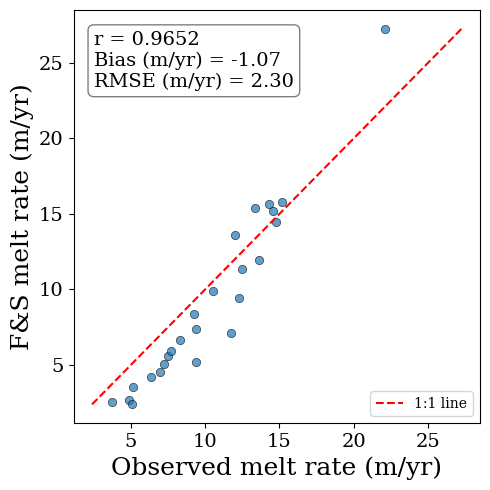

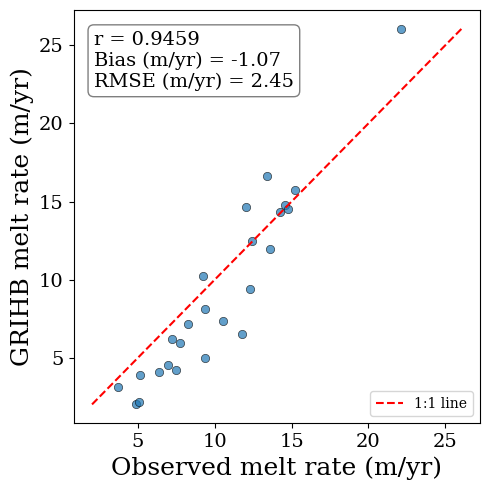

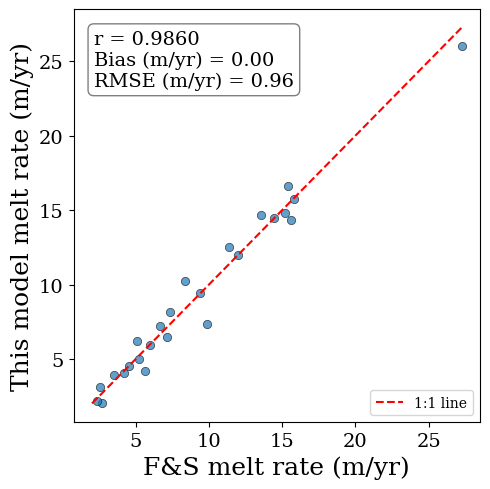

In [168]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('params_fix_w.csv')
df = df.dropna()

rho_2 = 1027.75
rho_i = 917
Lf    = 3.34e5
f     = 1e-4
C_p   = 3974
W0     = 100000
W = 150000

hub    = df['hub'].values
deltaT = df['Tcdw'].values
gprime = df['gprime'].values
s_ice  = df['s_ice'].values
s_bed  = df['s_bed'].values
melts  = df['melts'].values * 365 * 24 * 60 * 60
HCDW   = df['deltaH'].values
L      = df['L'].values * 1000

H_prime = -s_ice
D_prime = -s_bed
beta    = np.maximum((np.abs(hub) - 200 + s_bed * (250000 - L)) / HCDW - 1, 0)
print(f"Calculated beta values: {beta}")

k_no_alpha = C_p * deltaT * gprime * rho_2 / (rho_i * Lf * f) 

m_f_and_s_no_alpha = -k_no_alpha * H_prime * HCDW * 60 * 60 * 24 * 365/W0
m_soane_no_alpha   = (-k_no_alpha * L * H_prime * (D_prime - H_prime)
                      * 60 * 60 * 24 * 365 / 2 / (beta + 1))/W

def alpha_ols(obs, model):
    """OLS through origin — minimises sum of squared residuals."""
    return np.sum(obs * model) / np.sum(model**2)

def alpha_bias(obs, model):
    """Bias minimisation — forces mean prediction to equal mean observation."""
    return np.mean(obs) / np.mean(model)


alpha_fs_ols    = alpha_ols(melts,  m_f_and_s_no_alpha)
alpha_soane_ols = alpha_ols(melts,  m_soane_no_alpha)
alpha_fs_bias   = alpha_bias(melts, m_f_and_s_no_alpha)
alpha_soane_bias= alpha_bias(melts, m_soane_no_alpha)

print(f"\n--- OLS through origin ---")
print(f"  alpha (f_and_s): {alpha_fs_ols:.4f}")
print(f"  alpha (soane):   {alpha_soane_ols:.4f}")
print(f"\n--- Bias minimisation ---")
print(f"  alpha (f_and_s): {alpha_fs_bias:.4f}")
print(f"  alpha (soane):   {alpha_soane_bias:.4f}")

m_f_and_s = alpha_fs_ols    * m_f_and_s_no_alpha
m_soane   = alpha_soane_ols * m_soane_no_alpha


def add_stats(ax, x, y):
    r    = np.corrcoef(x, y)[0, 1]
    bias = np.mean(y - x)
    rmse = np.sqrt(np.mean((y - x)**2))
    ax.text(
        0.05, 0.95,
        f"r = {r:.4f}\nBias (m/yr) = {bias:.2f}\nRMSE (m/yr) = {rmse:.2f}",
        transform=ax.transAxes, va='top', fontsize=14,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.5)
    )


panels = [
    (melts,     m_f_and_s, 'Observed melt rate (m/yr)',  'F&S melt rate (m/yr)',      'F&S vs observed melts',        'fs_vs_observed'),
    (melts,     m_soane,   'Observed melt rate (m/yr)',  'GRIHB melt rate (m/yr)', 'GRIHB vs observed melts', 'grihb_vs_observed'),
    (m_f_and_s, m_soane,   'F&S melt rate (m/yr)',                 'This model melt rate (m/yr)',           'This model vs F&S',            'thismodel_vs_fs'),
]

for i, (x, y, xlabel, ylabel, title, fname) in enumerate(panels):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(x, y, alpha=0.7, edgecolors='k', linewidths=0.5)
    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lims, lims, 'r--', label='1:1 line')
    ax.set_xlabel(xlabel, fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.tick_params(axis='both', labelsize=14)
    ax.legend()
    add_stats(ax, x, y)
    plt.tight_layout()
    plt.savefig(f'{fname}_varW_zero_beta.pdf', bbox_inches='tight', pad_inches=0.1)
    plt.show()
    plt.close(fig)

In [169]:
# ── Alpha * Beta for m_soane ───────────────────────────────────────────────────
alpha_beta_ols  = alpha_soane_ols  / (beta+1)
alpha_beta_bias = alpha_soane_bias / (beta+1)



print(f"\n--- Alpha * Beta (m_soane) ---")
print(f"  OLS  — mean: {np.mean(alpha_beta_ols):.4f}, std: {np.std(alpha_beta_ols):.4f}")
print(f"  Bias — mean: {np.mean(alpha_beta_bias):.4f}, std: {np.std(alpha_beta_bias):.4f}")




--- Alpha * Beta (m_soane) ---
  OLS  — mean: 0.3190, std: 0.0745
  Bias — mean: 0.3558, std: 0.0830


Calculated beta values: [0.48118538 0.47453278 0.15749796 1.38493667 2.60210868 1.79116155
 0.98551853 0.928709   1.14261408 0.65593667 0.81138923 1.53433451
 1.30752268 1.19725961 0.84288768 0.57211086 1.0465155  0.27504843
 0.51719165 0.53908476 0.87441466 0.74581949 0.66548186 0.86328603
 0.56235409]
Optimal alpha (f_and_s): 0.1483
Optimal alpha (soane):   0.5761


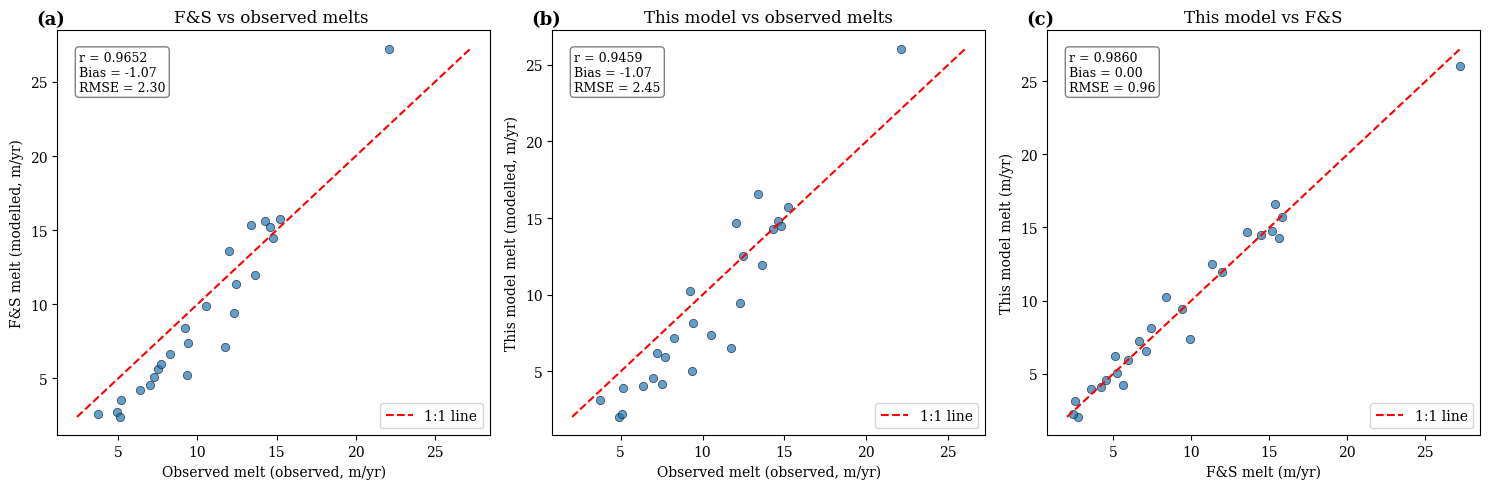

In [170]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('params_fix_w.csv')
df = df.dropna()  


rho_2 = 1027.75
rho_i = 917
Lf    = 3.34e5
f     = 1e-4
C_p   = 3974


hub    = df['hub'].values
deltaT    = df['Tcdw'].values      
gprime = df['gprime'].values
s_ice  = df['s_ice'].values
s_bed  = df['s_bed'].values
melts  = df['melts'].values * 365*24*60*60
HCDW   = df['deltaH'].values
L = df['L'].values*1000
W0 = 100000
W = 150000

H_prime = -s_ice
D_prime = -s_bed


beta = np.maximum((np.abs(hub)-200+s_bed*(250000-L))/(HCDW) -1, 0)

print(f"Calculated beta values: {beta}")

# compute models without alpha
k_no_alpha    = C_p * deltaT * gprime * rho_2 / (rho_i * Lf * f) 
m_f_and_s_no_alpha = -k_no_alpha * H_prime * HCDW * 60*60*24*365/W0
m_soane_no_alpha   = -k_no_alpha * L * H_prime * (D_prime - H_prime) * 60*60*24*365/2/ (beta + 1)/W

# find optimal alpha for each via OLS through origin
alpha_fs    = np.sum(melts * m_f_and_s_no_alpha) / np.sum(m_f_and_s_no_alpha**2)
alpha_soane = np.sum(melts * m_soane_no_alpha)   / np.sum(m_soane_no_alpha**2)
print(f'Optimal alpha (f_and_s): {alpha_fs:.4f}')
print(f'Optimal alpha (soane):   {alpha_soane:.4f}')

# compute final predictions with optimal alphas
m_f_and_s = alpha_fs    * m_f_and_s_no_alpha
m_soane   = alpha_soane * m_soane_no_alpha
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
def add_stats(ax, x, y):
    r    = np.corrcoef(x, y)[0, 1]
    bias = np.mean(y - x)
    rmse = np.sqrt(np.mean((y - x)**2))
    ax.text(
        0.05, 0.95,
        f"r = {r:.4f}\nBias = {bias:.2f}\nRMSE = {rmse:.2f}",
        transform=ax.transAxes, va='top', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.5)
    )


panels = [
    (melts,     m_f_and_s, 'Observed melt (observed, m/yr)',  'F&S melt (modelled, m/yr)', 'F&S vs observed melts '),
    (melts,     m_soane,   'Observed melt (observed, m/yr)',  'This model melt (modelled, m/yr)',   'This model vs observed melts'),
    (m_f_and_s, m_soane,   'F&S melt (m/yr)',        'This model melt (m/yr)',             'This model vs F&S'),
]



for ax, (x, y, xlabel, ylabel, title) in zip(axes, panels):
    ax.scatter(x, y, alpha=0.7, edgecolors='k', linewidths=0.5)
    lims = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lims, lims, 'r--', label='1:1 line')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    add_stats(ax, x, y)  # <-- add this

for i, ax in enumerate(axes):
    ax.text(-0.05, 1.05, f'({chr(97+i)})', transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top')

plt.tight_layout()
plt.savefig('combined_melt_plots_varW_zero_beta.png', dpi=150)
plt.show()

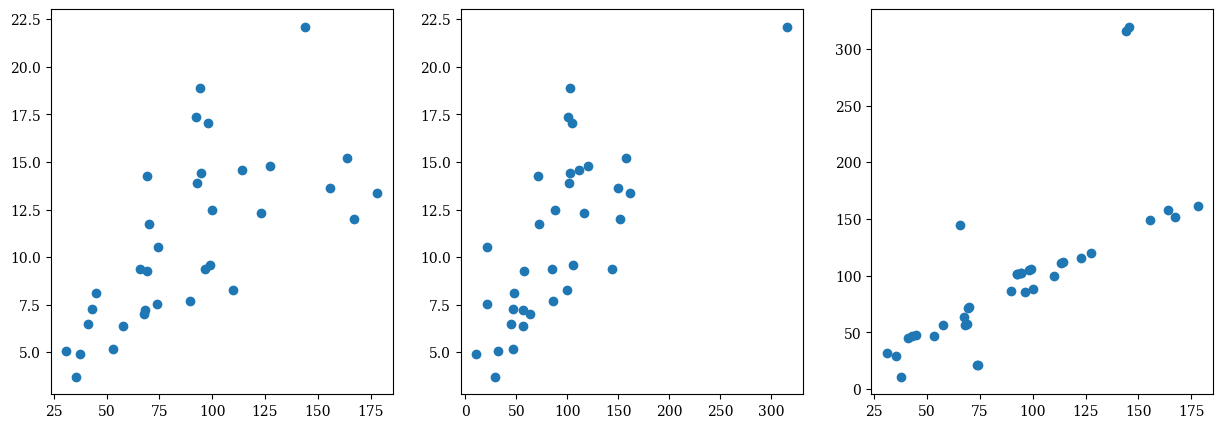

In [171]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('~/Downloads/params.csv')

rho_2 = 1027.75
rho_i = 917
Lf = 3.34e5
f = 1e-4
C_p = 3974
alpha = 0.184
L = 250000
W = 150000

hub = df['hub'].values
T2 = df['Tcdw'].values
gprime = df['gprime'].values
s_ice = df['s_ice'].values
s_bed = df['s_bed'].values
melts = df['melts'].values * 365*24*60*60
HCDW = df['deltaH'].values

H_prime = -s_ice
D_prime = -s_bed
beta = 0

k = alpha * C_p * (T2) * gprime * rho_2 / (rho_i * Lf * f) / W / (beta + 1)
m_pred = -k * H_prime * HCDW * 60*60*24*365 #Finucane and Stewart's model
m_avg = -k * L * H_prime * (D_prime - H_prime) * 60*60*24*365/2  #My model

fig,(ax1,ax2,ax3) = plt.subplots(1,3, figsize=(15,5))
ax1.scatter(m_pred,melts)
ax2.scatter(m_avg,melts)
ax3.scatter(m_pred,m_avg)
plt.show()


### change $h_2$ to HUB - H_gl

In [172]:
def m_average_min( y_gl, y_f, d_far, W, L, beta):
    H_prime = (y_f-y_gl)/L
    D_prime = (d_far-y_gl)/(250000)
    h_2 = np.abs(d_far-425)

    Tf = -1.8
    T2 = 0.5
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.094

    
    k = alpha*C_p*(T2 - Tf) * g * (rho_2 - rho_1) / (rho_i * Lf * f)/W/(beta+1)

    m_avg = -k*(H_prime)*h_2*60*60*24*364 # in m/yr
    return m_avg

In [173]:
def m_average_mid( y_gl, y_f, d_far, W, L, beta):
    H_prime = (y_f-y_gl)/L
    D_prime = (d_far-y_gl)/(250000)
    h_2 = np.abs(d_far-300)

    Tf = -1.8
    T2 = 0.5
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.094

    
    k = alpha*C_p*(T2 - Tf) * g * (rho_2 - rho_1) / (rho_i * Lf * f)/W/(beta+1)

    m_avg = -k*(H_prime)*h_2*60*60*24*364 # in m/yr
    return m_avg

In [174]:
def m_average_max( y_gl, y_f, d_far, W, L, beta):
    H_prime = (y_f-y_gl)/L
    D_prime = (d_far-y_gl)/(250000)
    h_2 = np.abs(d_far-600)

    Tf = -1.8
    T2 = 0.5
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.094

    
    k = alpha*C_p*(T2 - Tf) * g * (rho_2 - rho_1) / (rho_i * Lf * f)/W/(beta+1)

    m_avg = -k*(H_prime)*h_2*60*60*24*364 # in m/yr
    return m_avg

### Use typical melt velocities (10^{-4}=10^{-5} m/s, Jenkins 2016, Martin et al. 2011) to get a range for beta   

In [175]:
v = np.linspace(5e-2, 1e-1, 10000)


In [176]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

def M_vs_y(H, y_values, beta, D, T2, W):
  
     
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    L = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974
    k = (T2-Tf)*g*(rho_2-rho_1)*C_p/(rho_i*L*f*(beta+1))
    # Calculate H(y)
    H_values = H(y_values)

    m_values = -(H_values*(D-0.5*H_values)-0.5*D**2)*k # in m^3/s
    return m_values

1647.9640783405064


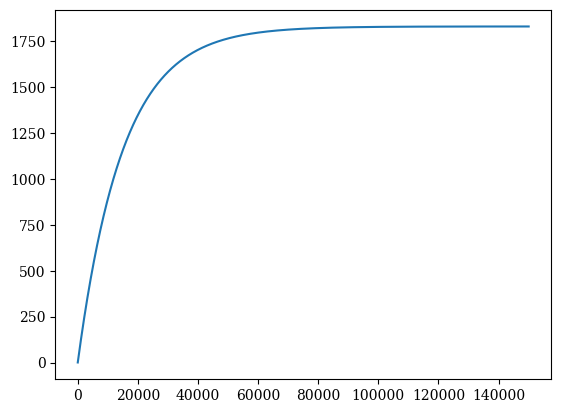

In [177]:
def beta(v, y_vals, H, M, D, T2, W):
    melt = M( H, y_vals, 0, D, T2, W )
    ice_depth = D-H(y_vals)
    ice_depth = D - H(y_vals)
    valid = ice_depth > 0         
    vbeta = melt[valid] / ice_depth[valid]
    v_avg = np.mean(v)
    beta = vbeta / v_avg

    return beta

beta = beta(v, y_vals, exp_H, M_vs_y, 600, 0.5, 500000 )

plt.plot(y_vals[1:], beta)
mean = np.mean(beta)
print(mean)

unrealistic

### Investigating the shape of the shelf and how this effects melt

1. For $H\sim\sqrt{y}$ and constant $D$
2. For exponential $H$ and constant $D$
3. For exponential $H$ and linear $D$

In [178]:
def m_linD_expH_max(y_vals, H_gl, H_f, D_f,  L,l, beta, T2, W):
   
    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    H_prime = -1/l * (H_gl - H_f) * np.exp(-y_vals / l)
    D = H_gl + (D_f - H_gl) * y_vals / L
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34*10**5
    f = 10**(-4)
    C_p = 3974
    alpha = 0.094
    k = alpha * (T2 - Tf) * g * (rho_2 - rho_1) * C_p / (rho_i * Lf * f * (beta + 1))
    m = -H_prime * (D - H) * k / W * 60 * 60 * 24 * 365
    
    max_idx = np.argmax(m)
    max_y = y_vals[max_idx] / 1000  # Convert to km
    
    return max_y

In [179]:
def m_linD_expH_max_value(y_vals, H_gl, H_f, D_f, L_domain, l, beta, T2, W):
    """
    Returns the maximum melt rate value
    """
    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    H_prime = -1/l * (H_gl - H_f) * np.exp(-y_vals / l)
    D = H_gl + (D_f - H_gl) * y_vals / L
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34*10**5
    f = 10**(-4)
    C_p = 3974
    alpha = 0.094
    k = alpha * (T2 - Tf) * g * (rho_2 - rho_1) * C_p / (rho_i * Lf * f * (beta + 1))
    m = -H_prime * (D - H) * k / W * 60 * 60 * 24 * 365
    
    
    return np.max(m)


In [180]:
# H sim sqrt(y)

def H_sqrt(y_vals):
    H = 600-np.sqrt(y_vals)
    return H

In [181]:
def D_quadratic(y_vals, b, c):
    D = 600 +b*y_vals + c*y_vals**2 
    return D

Slight peak as H' not defined at y=0

k = 0.021389040641101136
H_prime max = -0.001290997676266193
(D-H) max = 387.2983346207417
W = 100000
m_values max (m/s) = 1.512433568039796e-07
m_values max (m/yr) = 4.769610500170301


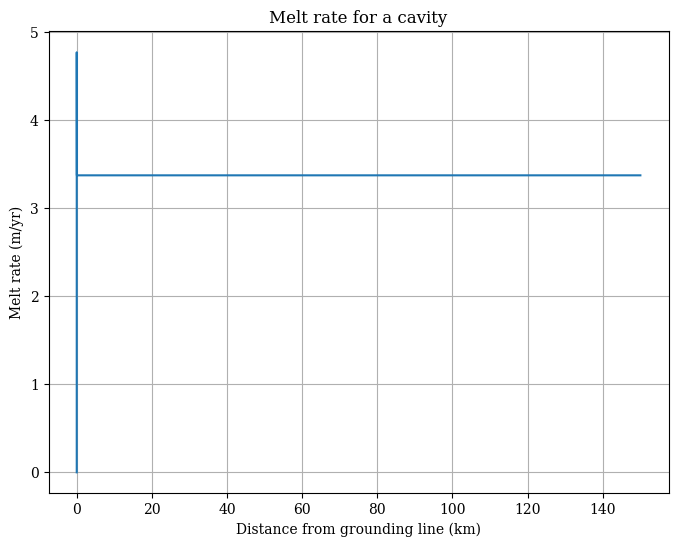

In [182]:
plot_m_vs_y(H_sqrt, y_vals, 2.8, 600, 1.5, 100000 )

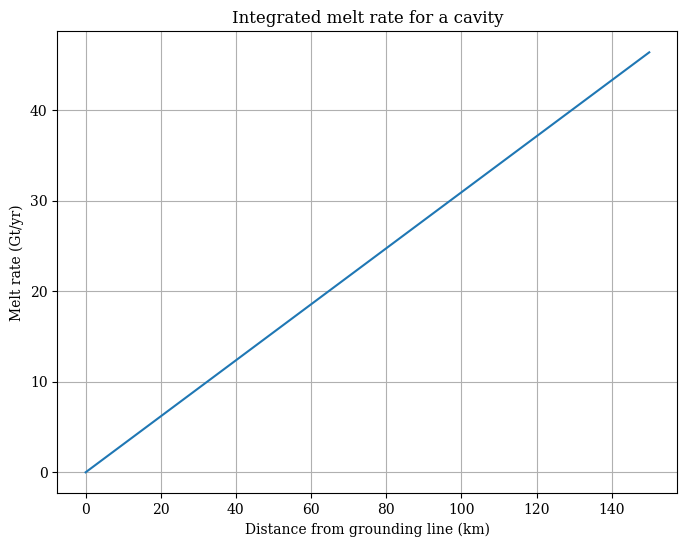

In [183]:
plot_M_vs_y(H_sqrt, y_vals, 2.8, 600, 1.5, 100000 )

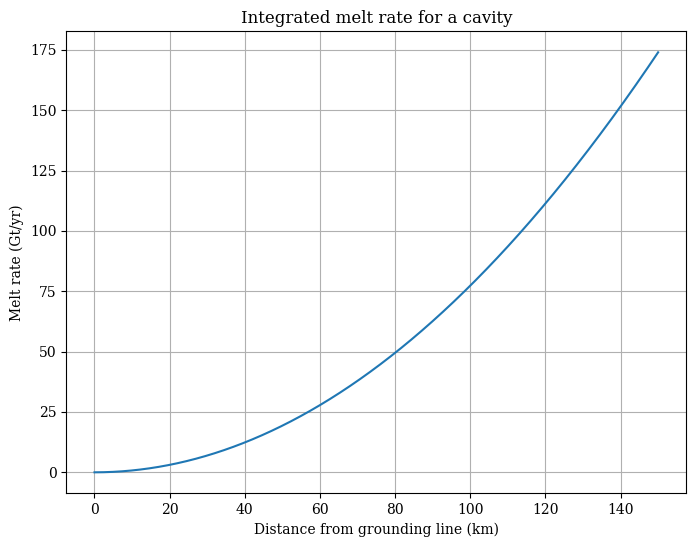

In [184]:
plot_M_vs_y(linear_H, y_vals, 2.8, 600, 1.5, 100000 )

2. Exponential

In [185]:
def exp_H1(y):
    H_gl = 600
    H_front = 150
    L = 15000
    return H_front + (H_gl - H_front) * np.exp(-y / (L))

In [186]:
def exp_H2(y):
    H_gl = 600
    H_front = 150
    L = 30000
    return H_front + (H_gl - H_front) * np.exp(-y / (L))

In [187]:
def exp_H3(y):
    H_gl = 600
    H_front = 150
    L = 100000
    return H_front + (H_gl - H_front) * np.exp(-y / (L))

In [188]:
def exp_H4(y):
    H_gl = 600
    H_front = 150
    L = 150000
    return H_front + (H_gl - H_front) * np.exp(-y / (L))

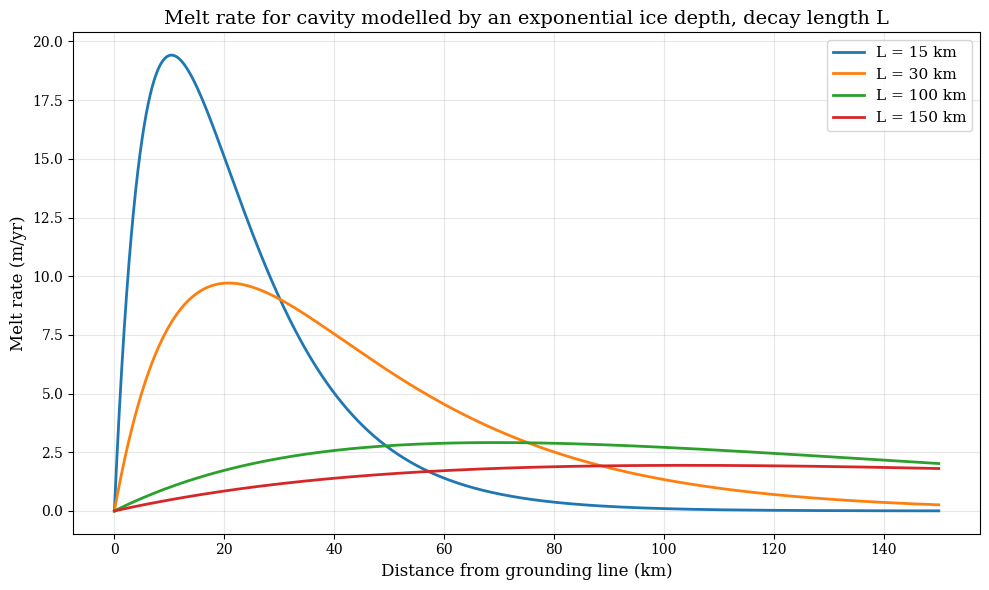

In [189]:
fig, ax = plt.subplots(figsize=(10, 6))

H_functions = [exp_H1, exp_H2, exp_H3, exp_H4]
L_values = [15000, 30000, 100000, 150000]

for i, (H_func, L) in enumerate(zip(H_functions, L_values)):
    # Manually plot instead of calling plot_m_vs_y
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34*10**5
    f = 10**(-4)
    C_p = 3974 
    alpha = 0.094
    g_prime = g*(rho_2-rho_1)/rho_2
    
    beta=2.8
    D=600
    T2 = 1
    W=100000
    k = alpha*C_p*(T2-Tf)*g_prime*rho_2/(rho_i*Lf*f*(beta+1))
    
    H_values = H_func(y_vals)
    H_prime = np.gradient(H_values, y_vals)
    m_values = -H_prime*(D-H_values)*k/W
    m_values_year = m_values*(60*60*24*365)
    
    ax.plot(y_vals/1000, m_values_year, label=f'L = {L/1000:.0f} km', linewidth=2)

ax.set_xlabel('Distance from grounding line (km)', fontsize=12)
ax.set_ylabel('Melt rate (m/yr)', fontsize=12)
ax.set_title('Melt rate for cavity modelled by an exponential ice depth, decay length L', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Now for exponential H and linear D

In [190]:
def m_linD_expH(y_vals, H_gl, H_f, D_f, L_domain, l, beta, T2, W, ax=None, label=None):
    """
    Cumulative melt for linear depth and exponential slope
    ax: matplotlib axes object (optional)
    label: label for legend (optional)
    """
    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    H_prime = -1/l * (H_gl - H_f) * np.exp(-y_vals / l)
    D = H_gl + (D_f - H_gl) * y_vals / L_domain
    
     
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34*10**5  #heat capacity
    f = 10**(-4)
    C_p = 3974
    alpha = 0.094
    k = alpha * (T2 - Tf) * g * (rho_2 - rho_1) * C_p / (rho_i * Lf * f * (beta + 1))
    m = -H_prime * (D - H) * k / W * 60 * 60 * 24 * 365
    
    if ax is None:
        ax = plt.gca()

    
    
    line= ax.plot(y_vals/1000, m, label=label, linewidth=2)
    line_color = line[0].get_color()

    ax.set_xlabel('y (km)', fontsize=12)
    ax.set_ylabel('M(y) (Gt/yr)', fontsize=12)
    ax.set_title('Cumulative melt for Thwaites glacier (linear sea bed, exponential ice thickness)')
    ax.grid(True, alpha=0.3)
    # Find the maximum melt and its location
    max_idx = np.argmax(m)
    max_y = y_vals[max_idx] / 1000  # Convert to km
    max_m = m[max_idx]
    
    # Add scatter point at maximum
    ax.scatter(max_y, max_m, s=100, zorder=5, color=line_color)
    
    # Add dotted lines to axes
    ax.axvline(max_y, color=line_color, linestyle=':', alpha=0.6)
    ax.axhline(max_m, color=line_color,  linestyle=':', alpha=0.6)
    
    ax.text(max_y, max_m+0.2, f'  {max_y:.0f} km', fontsize=11, va='bottom', ha='center')
    
    ax.set_xlabel('y (km)', fontsize=12)
    ax.set_ylabel('m(y) m/yr', fontsize=12)
    ax.set_title('Melt for  glacier (linear sea bed, exponential ice thickness)')
    ax.grid(True, alpha=0.3)

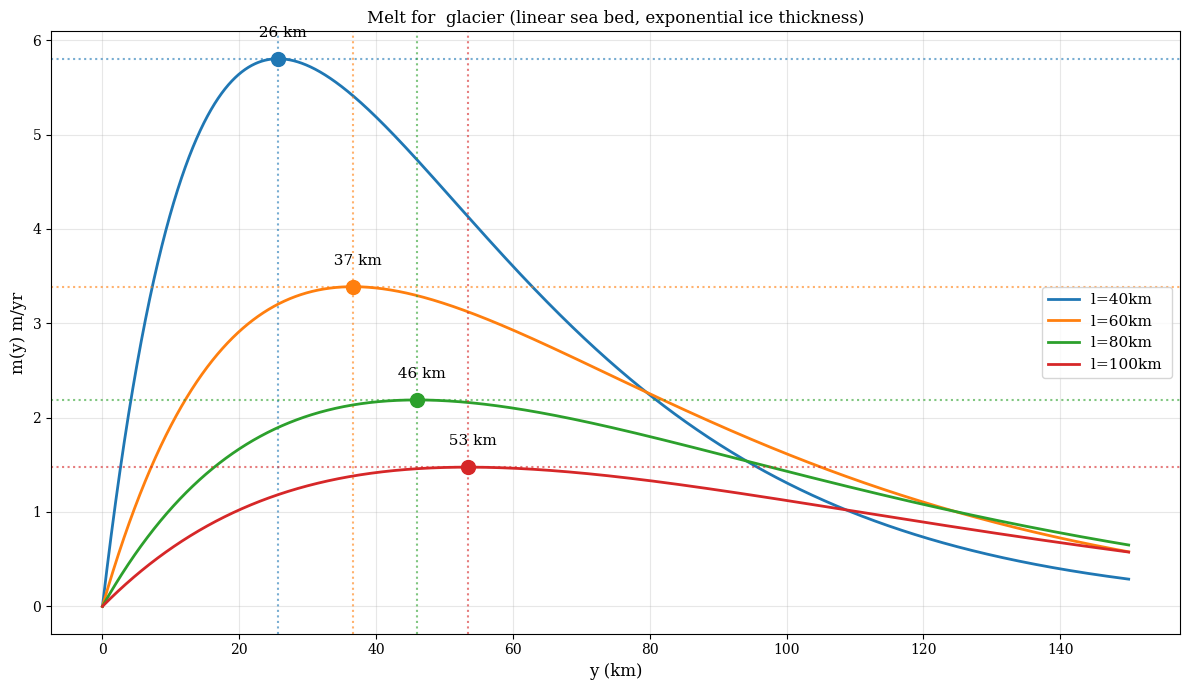

In [191]:
fig, ax = plt.subplots(figsize=(12, 7))

cases = [
    {'name': 'Case 1', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 2', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 60000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 3', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 80000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 3', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 100000, 'beta': 2.8, 'T2': 1, 'W': 100000},
]


for case in cases:
    delta_D = case['D_f']-case['H_gl']
    delta_H = case['H_gl']-case['H_f']
    Dd_DHL = delta_D/delta_H/case['L']
    label = f"l={case['l']/1000:.0f}km "
    m_linD_expH(y_vals, case['H_gl'], case['H_f'], case['D_f'], 
                         case['L'], case['l'], case['beta'], case['T2'], 
                         case['W'], ax=ax, label=label)

ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

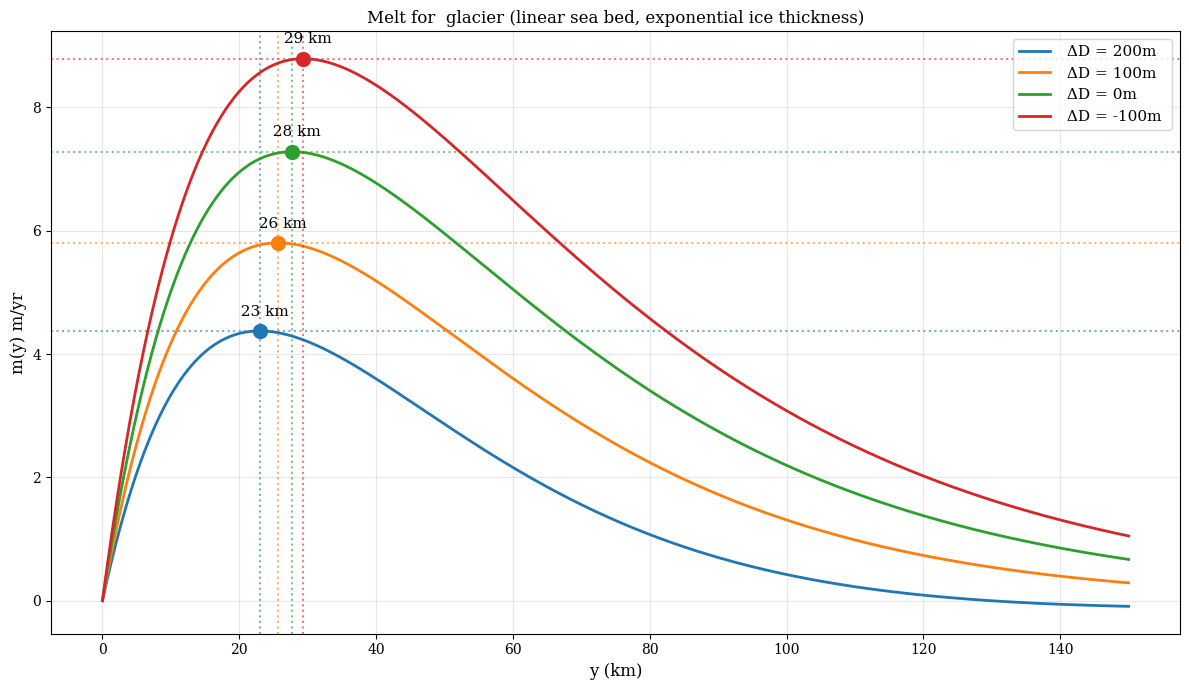

In [192]:
fig, ax = plt.subplots(figsize=(12, 7))

cases = [
    {'name': 'Case 1', 'H_gl': 600, 'H_f': 150, 'D_f': 400, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 2', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 3', 'H_gl': 600, 'H_f': 150, 'D_f': 600, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 4', 'H_gl': 600, 'H_f': 150, 'D_f': 700, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
]


for case in cases:
    delta_D = -case['D_f']+ case['H_gl']
    delta_H = case['H_gl']-case['H_f']
    Dd_DHL = delta_D/delta_H/case['L']
    label = f" ΔD = {delta_D:.0f}m "
    m_linD_expH(y_vals, case['H_gl'], case['H_f'], case['D_f'], 
                         case['L'], case['l'], case['beta'], case['T2'], 
                         case['W'], ax=ax, label=label)

ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

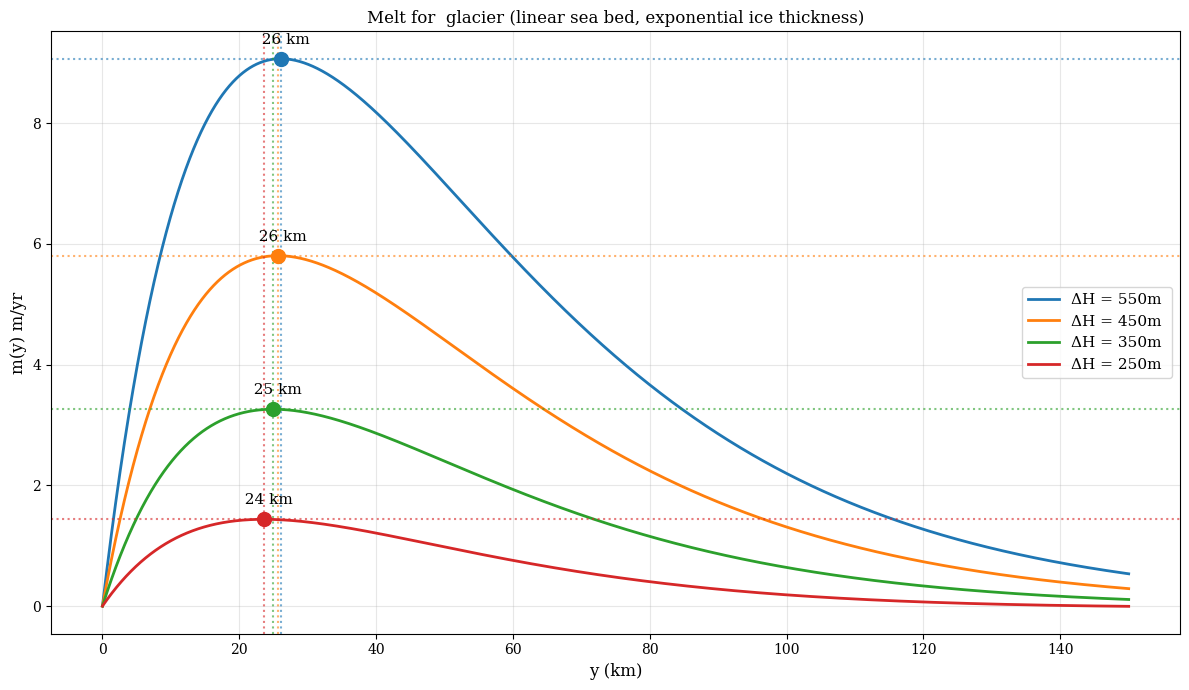

In [193]:
fig, ax = plt.subplots(figsize=(12, 7))

cases = [
    {'name': 'Case 1', 'H_gl': 600, 'H_f': 50, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 2', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 3', 'H_gl': 600, 'H_f': 250, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 3', 'H_gl': 600, 'H_f': 350, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
]


for case in cases:
    delta_D = case['D_f']-case['H_gl']
    delta_H = case['H_gl']-case['H_f']
    Dd_DHL = delta_D/delta_H/case['L']
    label = f"ΔH = {delta_H:.0f}m "
    m_linD_expH(y_vals, case['H_gl'], case['H_f'], case['D_f'], 
                         case['L'], case['l'], case['beta'], case['T2'], 
                         case['W'], ax=ax, label=label)

ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

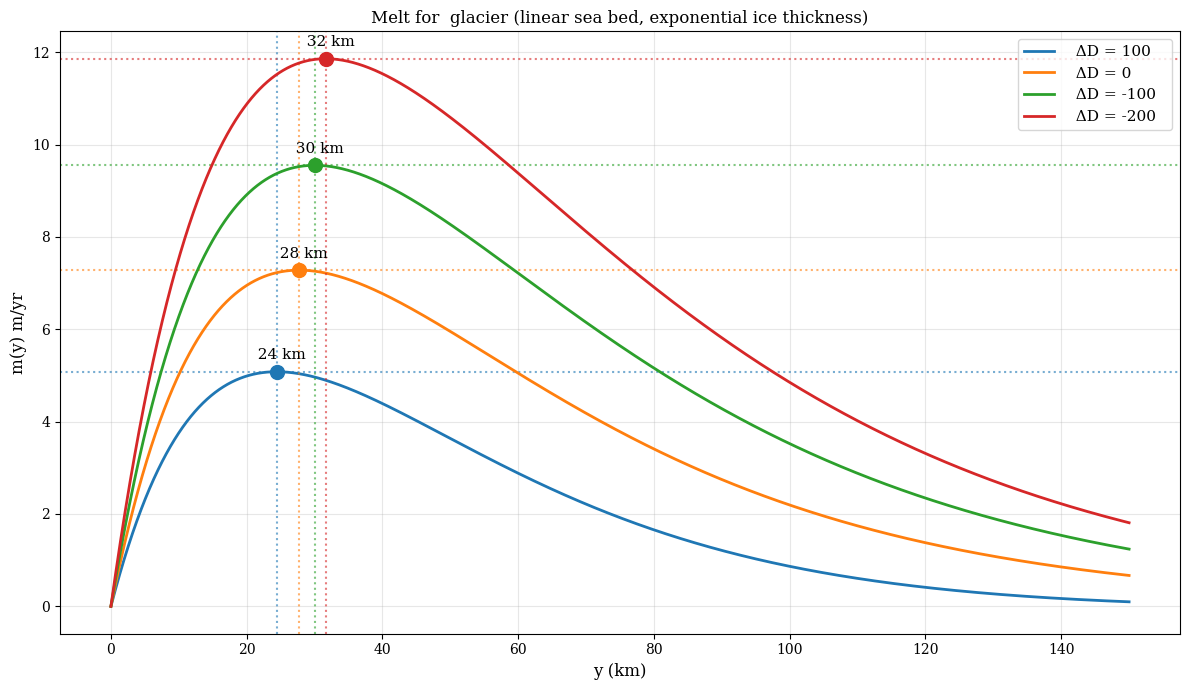

In [194]:
fig, ax = plt.subplots(figsize=(12, 7))

cases = [
    {'name': 'Case 4', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},

    {'name': 'Case 1', 'H_gl': 600, 'H_f': 150, 'D_f': 600, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},
    {'name': 'Case 2', 'H_gl': 600, 'H_f': 150, 'D_f': 700, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},

    {'name': 'Case 3', 'H_gl': 600, 'H_f': 150, 'D_f': 800, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 100000},

   

]


for case in cases:
    delta_D = -case['D_f']+case['H_gl']
    delta_H = case['H_gl']-case['H_f']
    Dd_DHL = delta_D/delta_H/case['L']
    label = f"  ΔD = {delta_D}  "
    m_linD_expH(y_vals, case['H_gl'], case['H_f'], case['D_f'], 
                         case['l'], case['l'], case['beta'], case['T2'], 
                         case['W'], ax=ax, label=label)

ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

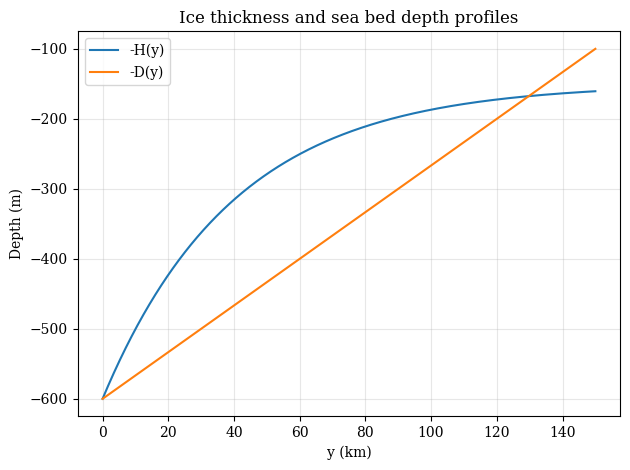

In [195]:
H_gl = 600

y_vals = np.linspace(0, 150000, 1000)
H_f = 150
D_f = 400
L = 60000
l = 40000
beta = 2.8
T2 = 1
W = 100000
H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
H_prime = -1/l * (H_gl - H_f) * np.exp(-y_vals / l)
D = H_gl + (D_f - H_gl) * y_vals / L
y_vals = np.linspace(0, 150000, 1000)

plt.plot(y_vals/1000, -H, label='-H(y)')
plt.plot(y_vals/1000, -D, label='-D(y)')
plt.xlabel('y (km)')
plt.ylabel('Depth (m)')
plt.title('Ice thickness and sea bed depth profiles')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()


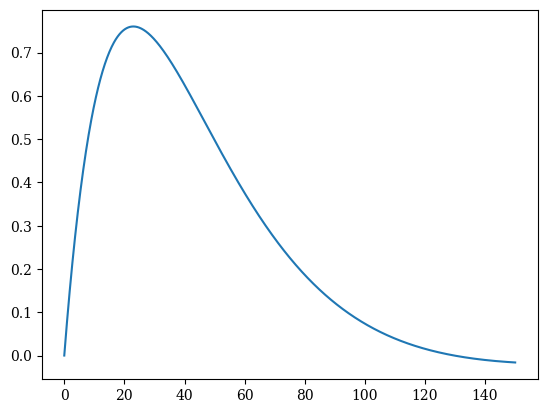

In [196]:

plt.plot(y_vals/1000, -H_prime*(D-H), label="H'(y)")

negative melt rate? for D=-200 which is an downwards sloping sea bed

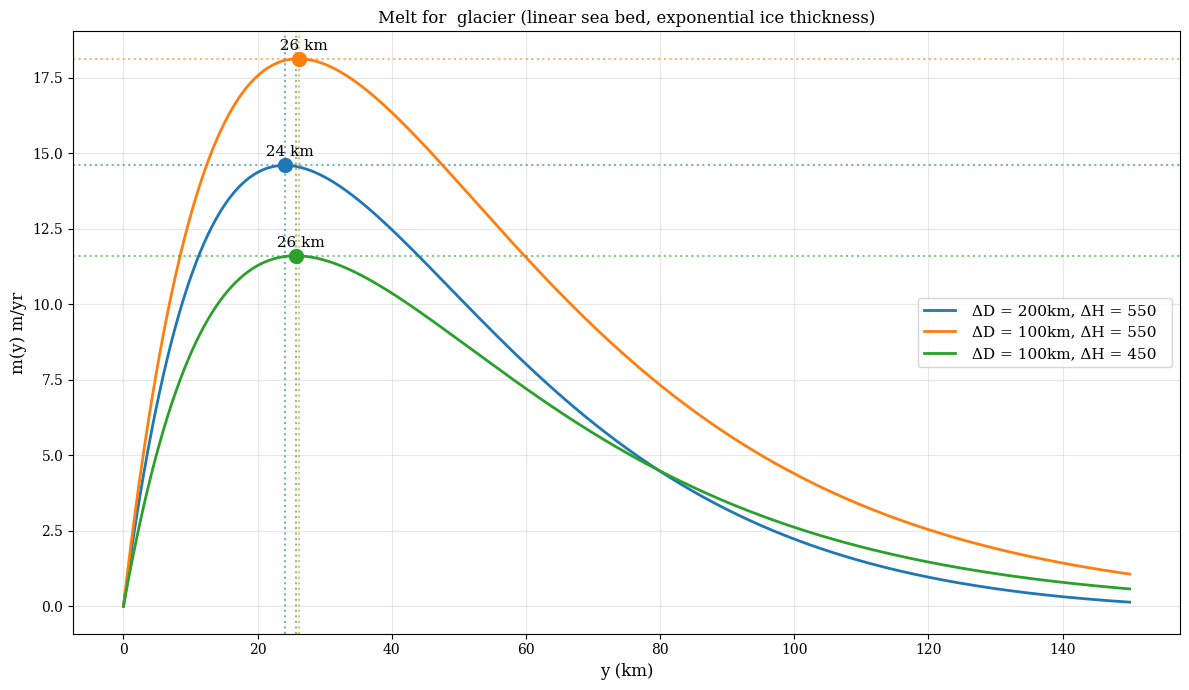

In [197]:
fig, ax = plt.subplots(figsize=(12, 7))

# Define your cases
cases = [

    {'name': 'Case 3', 'H_gl': 600, 'H_f': 50, 'D_f': 400, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 50000},
    {'name': 'Case 2', 'H_gl': 600, 'H_f': 50, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 50000},
    
    {'name': 'Case 1', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2.8, 'T2': 1, 'W': 50000},
    
]


for case in cases:
    delta_D = -case['D_f']+case['H_gl']
    delta_H = case['H_gl']-case['H_f']
    Dd_DHL = delta_D/delta_H/case['L']
    label = f" ΔD = {delta_D:.0f}km, ΔH = {delta_H}  "
    m_linD_expH(y_vals, case['H_gl'], case['H_f'], case['D_f'], 
                         case['L'], case['l'], case['beta'], case['T2'], 
                         case['W'], ax=ax, label=label)

ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

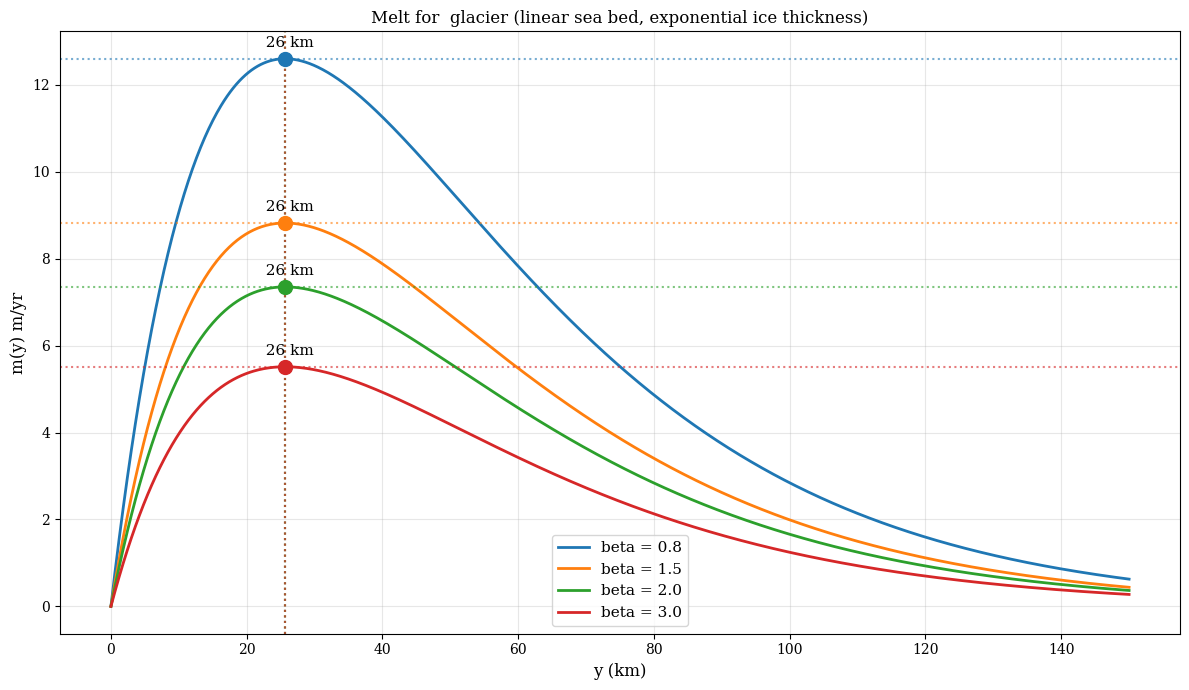

In [198]:
fig, ax = plt.subplots(figsize=(12, 7))

cases = [
    {'name': 'Case 1', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 0.75, 'T2': 1, 'W': 100000},
    {'name': 'Case 2', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 1.5, 'T2': 1, 'W': 100000},
    {'name': 'Case 3', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 2, 'T2': 1, 'W': 100000},
    {'name': 'Case 3', 'H_gl': 600, 'H_f': 150, 'D_f': 500, 'L': 60000, 'l': 40000, 'beta': 3, 'T2': 1, 'W': 100000},
]


for case in cases:
    delta_D = case['D_f']-case['H_gl']
    delta_H = case['H_gl']-case['H_f']
    Dd_DHL = delta_D/delta_H/case['L']
    label = f"beta = {case['beta']:.1f}"
    m_linD_expH(y_vals, case['H_gl'], case['H_f'], case['D_f'], 
                         case['L'], case['l'], case['beta'], case['T2'], 
                         case['W'], ax=ax, label=label)

ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

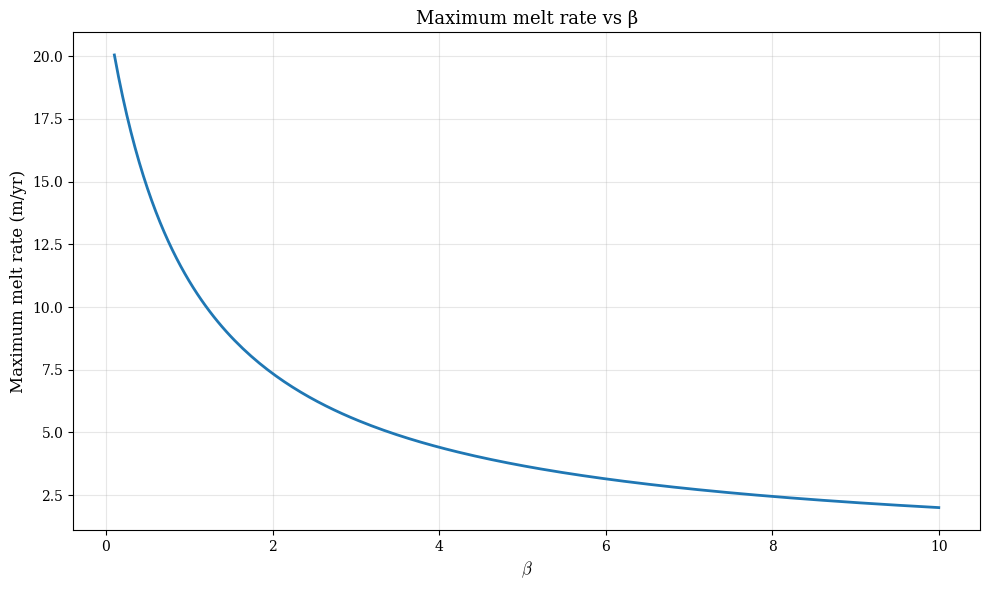

In [199]:
def m_linD_expH_max_value(y_vals, H_gl, H_f, D_f, l, beta, T2, W):
    L = 60000

    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    H_prime = -1/l * (H_gl - H_f) * np.exp(-y_vals / l)
    D = H_gl + (D_f - H_gl) * y_vals / L

    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.094

    k = alpha * (T2 - Tf) * g * (rho_2 - rho_1) * C_p / (rho_i * Lf * f * (beta + 1))

    m = -H_prime * (D - H) * k / W * 60 * 60 * 24 * 365

    return np.max(m)
beta_values = np.linspace(0.1, 10, 200)
H_gl = 600
H_f = 150
D_f = 500
l = 40000
T2 = 1
W = 100000

y_vals = np.linspace(0, 60000, 1000)

max_melt = np.zeros_like(beta_values)

for i, beta in enumerate(beta_values):
    max_melt[i] = m_linD_expH_max_value(
        y_vals, H_gl, H_f, D_f, l, beta, T2, W
    )

fig, ax = plt.subplots(figsize=(10,6))

ax.plot(beta_values, max_melt, linewidth=2)


ax.set_xlabel(r'$\beta$', fontsize=12)
ax.set_ylabel('Maximum melt rate (m/yr)', fontsize=12)
ax.set_title('Maximum melt rate vs β', fontsize=13)

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


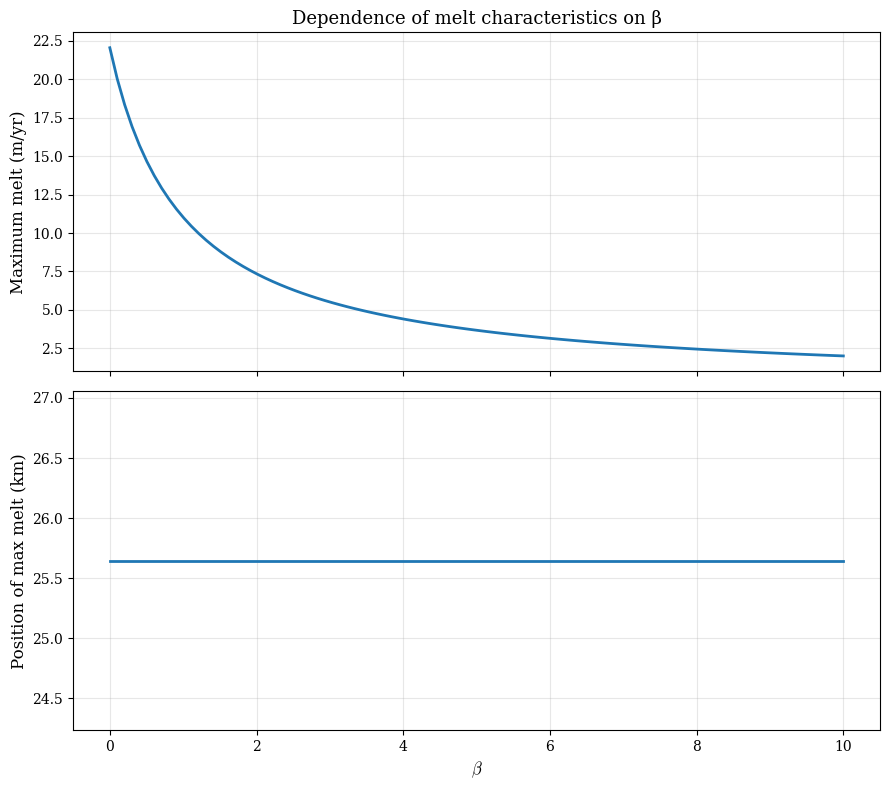

In [200]:
beta_values = np.linspace(0,10, 100)  # 0.01 → 10

y_vals = np.linspace(0, 60000, 1000)
L = 60000
H_gl = 600
H_f = 150
D_f = 500
l = 40000
T2 = 1
W = 100000

max_melt = np.zeros_like(beta_values)
max_position = np.zeros_like(beta_values)

for i, beta in enumerate(beta_values):
    max_melt[i] = m_linD_expH_max_value(
        y_vals, H_gl, H_f, D_f, l, beta, T2, W)
    max_position[i] = m_linD_expH_max(
        y_vals, H_gl, H_f, D_f, L,l, beta, T2, W
    )

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

# ---- Top: Maximum melt ----
ax1.plot(beta_values, max_melt, linewidth=2)
ax1.set_ylabel('Maximum melt (m/yr)', fontsize=12)

ax1.grid(True, which='both', alpha=0.3)
ax1.set_title('Dependence of melt characteristics on β', fontsize=13)

# ---- Bottom: Position of maximum ----
ax2.plot(beta_values, max_position, linewidth=2)
ax2.set_xlabel(r'$\beta$', fontsize=12)
ax2.set_ylabel('Position of max melt (km)', fontsize=12)

ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

Location doesn't change but rate does

In [201]:
shelf_points = {
  "Thwaites": {
    "l": 19.636431235773028,
    "b": 5.702448287539313,
    "cavity_length": 80.0,
    "delta_D_over_L": -5.702448287539313
  },
  "Dotson": {
    "l": 29.93230650933973,
    "b": -29.028095505184844,
    "cavity_length": 125.0,
    "delta_D_over_L": 29.028095505184844
  },
  "Crosson": {
    "l": 18.834636414301894,
    "b": 9.074161804359925,
    "cavity_length": 65.0,
    "delta_D_over_L": -9.074161804359925
  },
  "PineIsland_East": {
    "l": 9.097746789670655,
    "b": 6.638130684973615,
    "cavity_length": 60.0,
    "delta_D_over_L": -6.638130684973615
  },
  
  "Ross": {
    "l": 63.08031563265784,
    "b": 0.09048834431969029,
    "cavity_length": 900.0,
    "delta_D_over_L": -0.09048834431969029
  },
  "Fimbul": {
    "l": 32.559606139869096,
    "b": -6.225929045444378,
    "cavity_length": 239.5,
    "delta_D_over_L": 6.225929045444378
  },
  "Moscow_University": {
    "l": 105.3708003983872,
    "b": 6.791898465347074,
    "cavity_length": 162.5,
    "delta_D_over_L": -6.791898465347074
  },
  
}

In [202]:
shelf_points = {
  "Thwaites": {
    "l": 19.636431235773028,
    "cavity_length": 80.0,
    "H_gl_minus_Df_over_L": -6.912118356665277
  },
  "Dotson": {
    "l": 29.93230650933973,
    "cavity_length": 125.0,
    "H_gl_minus_Df_over_L": 1.5002809660399912
  },
  "Crosson": {
    "l": 18.834636414301894,
    "cavity_length": 65.0,
    "H_gl_minus_Df_over_L": 4.149221552357216
  },
  "PineIsland_East": {
    "l": 9.097746789670655,
    "cavity_length": 60.0,
    "H_gl_minus_Df_over_L": -5.059309940332969
  },
  
  "Ross": {
    "l": 63.08031563265784,
    "cavity_length": 900.0,
    "H_gl_minus_Df_over_L": 0.17179059625934073
  },
  "Fimbul": {
    "l": 32.559606139869096,
    "cavity_length": 239.5,
    "H_gl_minus_Df_over_L": 3.410010982531958
  },
  "Moscow_University": {
    "l": 105.3708003983872,
    "cavity_length": 162.5,
    "H_gl_minus_Df_over_L": 5.6532094713287195
  },
  
}

[<function matplotlib.pyplot.show(close=None, block=None)>]

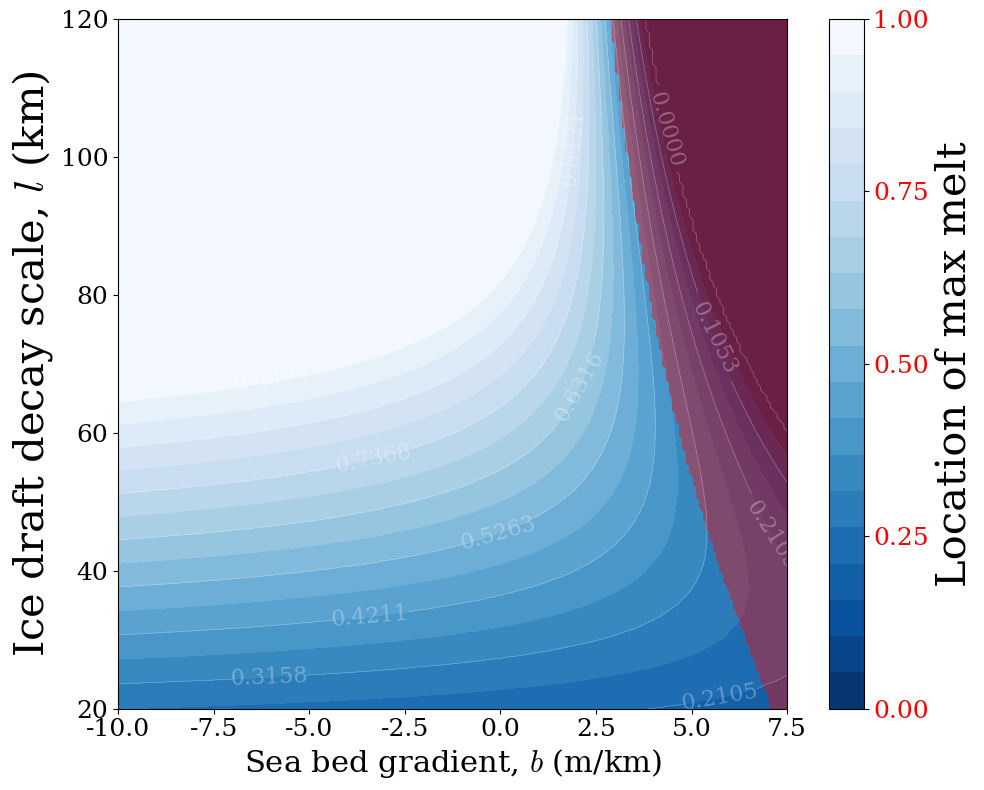

In [203]:
# Define parameter ranges
l_values = np.linspace(20000, 120000, 200)  # decay scale in meters
D_f_values = np.linspace(150, 1200, 200)

max_melt_location = np.zeros((len(l_values), len(D_f_values)))


H_gl = 600
H_f = 150
beta = 2.8
T2 = 1
W = 100000
L = 60000
D_f_grid, l_grid = np.meshgrid(D_f_values, l_values)
H_end_grid = H_f + (H_gl - H_f) * np.exp(-L / l_grid)

# Build mask: True where min(D(y) - H(y)) < 0 for any y
mask = np.zeros((len(l_values), len(D_f_values)))
for i, l in enumerate(l_values):
    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    for j, D_f in enumerate(D_f_values):
        D = H_gl + (D_f - H_gl) * y_vals / L
        mask[i, j] = np.min(D - H)  # negative if D < H anywhere
delta_D = -D_f_values + H_gl


for i, l in enumerate(l_values):
    for j, d in enumerate(D_f_values):
        max_melt_location[i, j] = m_linD_expH_max(y_vals, H_gl, H_f, d, L, l, beta, T2, W)
# Create heatmap
fig, ax = plt.subplots(figsize=(10, 8))
normalised_max_melt_location = max_melt_location / 60
levels = np.linspace(0, 1, 20)

im = ax.contourf(delta_D, l_values/1000, normalised_max_melt_location, 
                 levels=levels, vmin=0, vmax=1, cmap='Blues_r')

contours = ax.contour(delta_D, l_values/1000, normalised_max_melt_location, 
                      levels=levels[::2], colors='white', alpha=0.3, linewidths=0.5)
ax.clabel(contours, inline=True, fontsize=16)

# Red overlay where D_f > H[-1]
ax.contourf(delta_D, l_values/1000, mask, levels=[-np.inf, -1e-10], colors=['red'], alpha=0.4)
ax.contour(delta_D, l_values/1000, mask, levels=[0], colors='red', linewidths=1.5)

cbar = plt.colorbar(im, ax=ax, ticks=np.linspace(0, 1, 5))
cbar.set_label('Location of max melt', fontsize=30)

cbar.ax.tick_params(labelsize=18, color='black', labelcolor='red')

ax.set_ylabel('Ice draft decay scale, $l$ (km)', fontsize=30)
L_km = L / 1000  # 60 km
L_km = L / 1000  # 60

tick_gradients = np.array([-10,-7.5,-5, -2.5, 0, 2.5, 5, 7.5])  

tick_positions = tick_gradients * L_km                    

ax.set_xticks(tick_positions)
ax.set_xticklabels([str(g) for g in tick_gradients])
ax.set_xlabel('Sea bed gradient, $b$ (m/km)', fontsize=22)
ax.tick_params(axis='both', labelsize=18    )
plt.tight_layout()
plt.savefig('max_melt_location_heatmap.png', bbox_inches='tight', pad_inches=0.1)
[plt.show]

[<function matplotlib.pyplot.show(close=None, block=None)>]

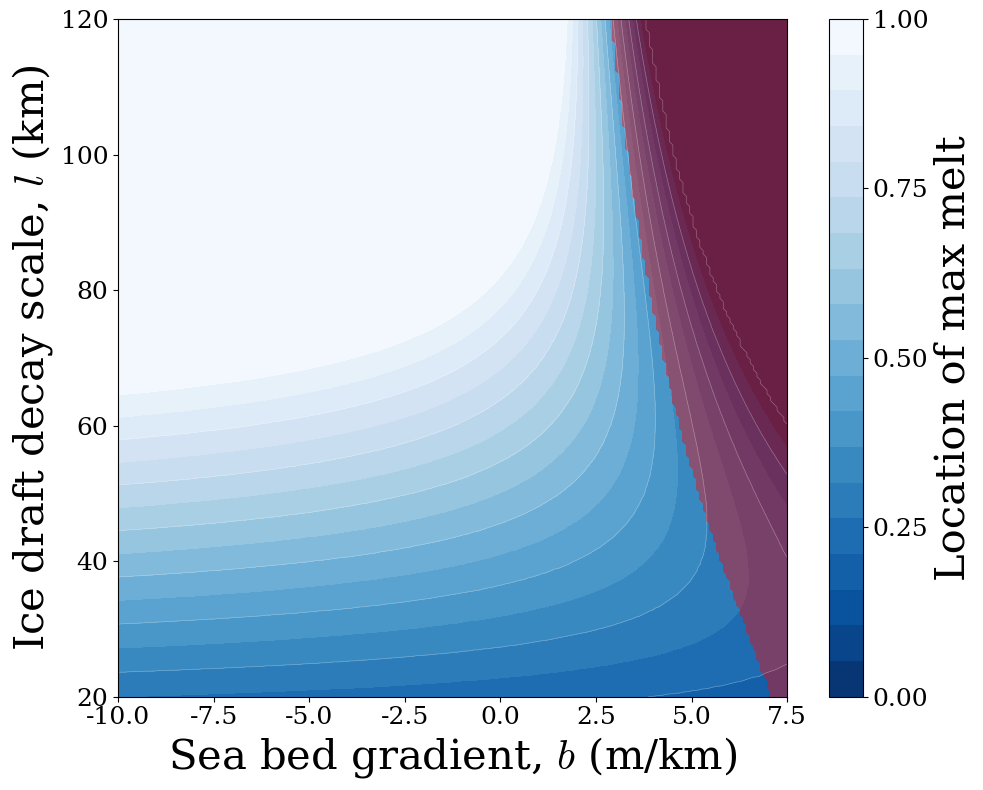

In [204]:

l_values = np.linspace(20000, 120000, 200)  
D_f_values = np.linspace(150, 1200, 200)

max_melt_location = np.zeros((len(l_values), len(D_f_values)))


H_gl = 600
H_f = 150
beta = 2.8
T2 = 1
W = 100000
L = 60000
D_f_grid, l_grid = np.meshgrid(D_f_values, l_values)
H_end_grid = H_f + (H_gl - H_f) * np.exp(-L / l_grid)  

# Build mask: True where min(D(y) - H(y)) < 0 for any y
mask = np.zeros((len(l_values), len(D_f_values)))
for i, l in enumerate(l_values):
    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    for j, D_f in enumerate(D_f_values):
        D = H_gl + (D_f - H_gl) * y_vals / L
        mask[i, j] = np.min(D - H)  # negative if D < H anywhere
delta_D = -D_f_values + H_gl

for i, l in enumerate(l_values):
    for j, d in enumerate(D_f_values):
        max_melt_location[i, j] = m_linD_expH_max(y_vals, H_gl, H_f, d, L, l, beta, T2, W)

fig, ax = plt.subplots(figsize=(10, 8))
normalised_max_melt_location = max_melt_location / 60
levels = np.linspace(0, 1, 20)

im = ax.contourf(delta_D, l_values/1000, normalised_max_melt_location, 
                 levels=levels, vmin=0, vmax=1, cmap='Blues_r')
# White contour lines
contours = ax.contour(delta_D, l_values/1000, normalised_max_melt_location, 
                      levels=levels[::2], colors='white', alpha=0.3, linewidths=0.5)

# Red overlay where D_f > H[-1]
ax.contourf(delta_D, l_values/1000, mask, levels=[-np.inf, -1e-10], colors=['red'], alpha=0.4)
ax.contour(delta_D, l_values/1000, mask, levels=[0], colors='red', linewidths=1.5)
# Colorbar 
cbar = plt.colorbar(im, ax=ax, ticks=np.linspace(0, 1, 5))
cbar.set_label('Location of max melt', fontsize=30)


cbar.ax.tick_params(labelsize=18, color='black', labelcolor='black')

ax.set_ylabel('Ice draft decay scale, $l$ (km)', fontsize=30)

L_km = L / 1000  # 60 km
L_km = L / 1000  # 60

tick_gradients = np.array([-10,-7.5,-5, -2.5, 0, 2.5, 5, 7.5])  
tick_positions = tick_gradients * L_km                    

ax.set_xticks(tick_positions)
ax.set_xticklabels([str(g) for g in tick_gradients])
ax.set_xlabel('Sea bed gradient, $b$ (m/km)', fontsize=30)
ax.tick_params(axis='both', labelsize=18    )
plt.tight_layout()
plt.savefig('max_melt_location_heatmap.pdf', bbox_inches='tight', pad_inches=0.1)
[plt.show]

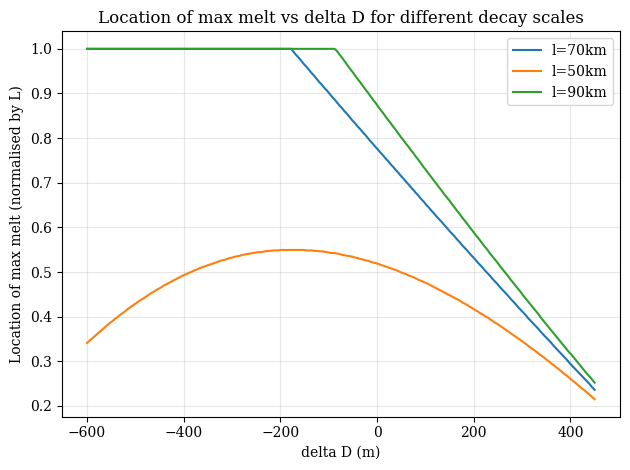

In [205]:
plt.plot(delta_D, normalised_max_melt_location[:,100], label='l=70km')
plt.plot(delta_D, normalised_max_melt_location[:,50], label='l=50km')
plt.plot(delta_D, normalised_max_melt_location[:,150], label='l=90km')
plt.xlabel('delta D (m)')
plt.ylabel('Location of max melt (normalised by L)')
plt.title('Location of max melt vs delta D for different decay scales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

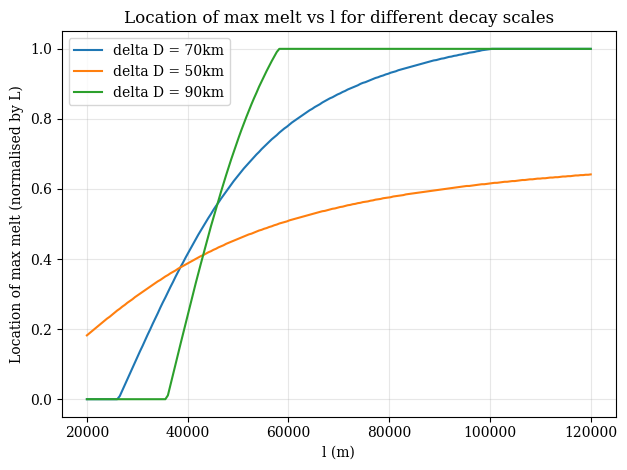

In [206]:
plt.plot(l_values, normalised_max_melt_location[100,:], label='delta D = 70km')
plt.plot(l_values, normalised_max_melt_location[50,:], label='delta D = 50km')
plt.plot(l_values, normalised_max_melt_location[150,:], label='delta D = 90km')
plt.xlabel('l (m)')
plt.ylabel('Location of max melt (normalised by L)')
plt.title('Location of max melt vs l for different decay scales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

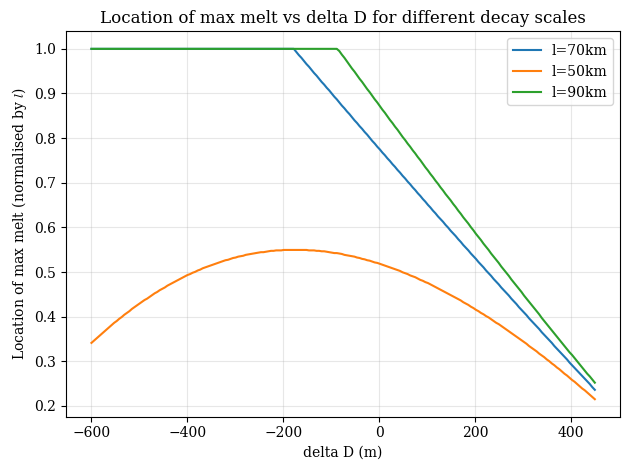

In [207]:
plt.plot(delta_D, normalised_max_melt_location[:,100], label='l=70km')
plt.plot(delta_D, normalised_max_melt_location[:,50], label='l=50km')
plt.plot(delta_D, normalised_max_melt_location[:,150], label='l=90km')
plt.xlabel('delta D (m)')
plt.ylabel('Location of max melt (normalised by $l$)')
plt.title('Location of max melt vs delta D for different decay scales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

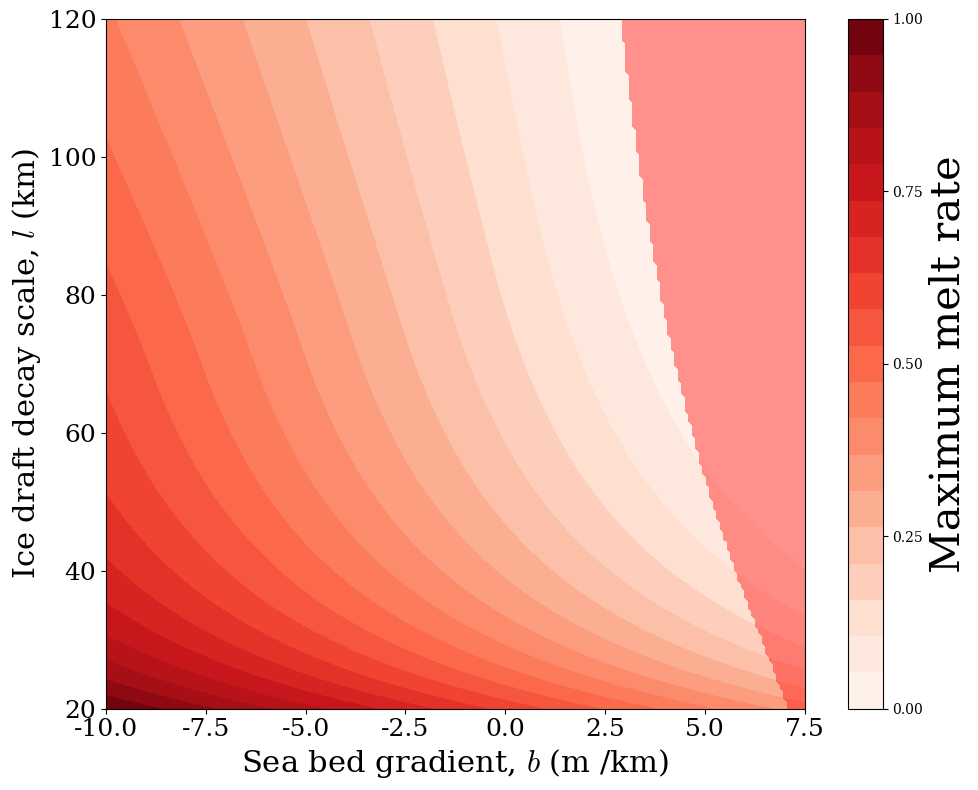

In [208]:

l_values = np.linspace(20000, 120000, 200)  # decay scale in meters
D_f_values = np.linspace(150, 1200, 200)       
                                      

H_gl = 600
H_f = 150
beta = 2.8
T2 = 1
W = 100000
L = 60000

delta_D = -D_f_values + H_gl


max_melt_value = np.zeros((len(l_values), len(D_f_values)))

delta_D = H_gl-D_f_values
D_f_grid, l_grid = np.meshgrid(D_f_values, l_values)
H_end_grid = H_f + (H_gl - H_f) * np.exp(-L / l_grid)  

mask = np.zeros((len(l_values), len(D_f_values)))

for i, l in enumerate(l_values):
    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    for j, D_f in enumerate(D_f_values):
        D = H_gl + (D_f - H_gl) * y_vals / L
        mask[i, j] = np.min(D - H)  # negative if D < H anywhere

for i, l in enumerate(l_values):
    for j, D_f in enumerate(D_f_values):
        max_melt_value[i, j] = m_linD_expH_max_value(y_vals, H_gl, H_f, D_f, l, beta, T2, W)


# Plot it
fig, ax = plt.subplots(figsize=(10, 8))
max_melt_norm = max_melt_value / np.max(max_melt_value)

im = ax.contourf(delta_D, l_values/1000, max_melt_norm, levels=np.linspace(0, 1, 20), cmap='Reds')
#  Red overlay where D_f > H[-1]
ax.contourf(delta_D, l_values/1000, mask, levels=[-np.inf, -1e-10], colors=['red'], alpha=0.4)
ax.contour(delta_D, l_values/1000, mask, levels=[0], colors='red', linewidths=1.5)


cbar = plt.colorbar(im, ax=ax, ticks=np.linspace(0, 1, 5))
cbar.set_label('Maximum melt rate', fontsize=30)

L_km = L / 1000  # 60 km
L_km = L / 1000  # 60

tick_gradients = np.array([-10,-7.5,-5, -2.5, 0, 2.5, 5, 7.5])  
tick_positions = tick_gradients * L_km                    

ax.set_xticks(tick_positions)
ax.set_xticklabels([str(g) for g in tick_gradients])
ax.set_xlabel('Sea bed gradient, $b$ (m /km)', fontsize=22)
ax.tick_params(axis='both', labelsize=18)
ax.set_ylabel('Ice draft decay scale, $l$ (km)', fontsize=22)
plt.tight_layout()

plt.savefig('max_melt_value_heatmap.png', bbox_inches='tight', pad_inches=0.1)
plt.show()


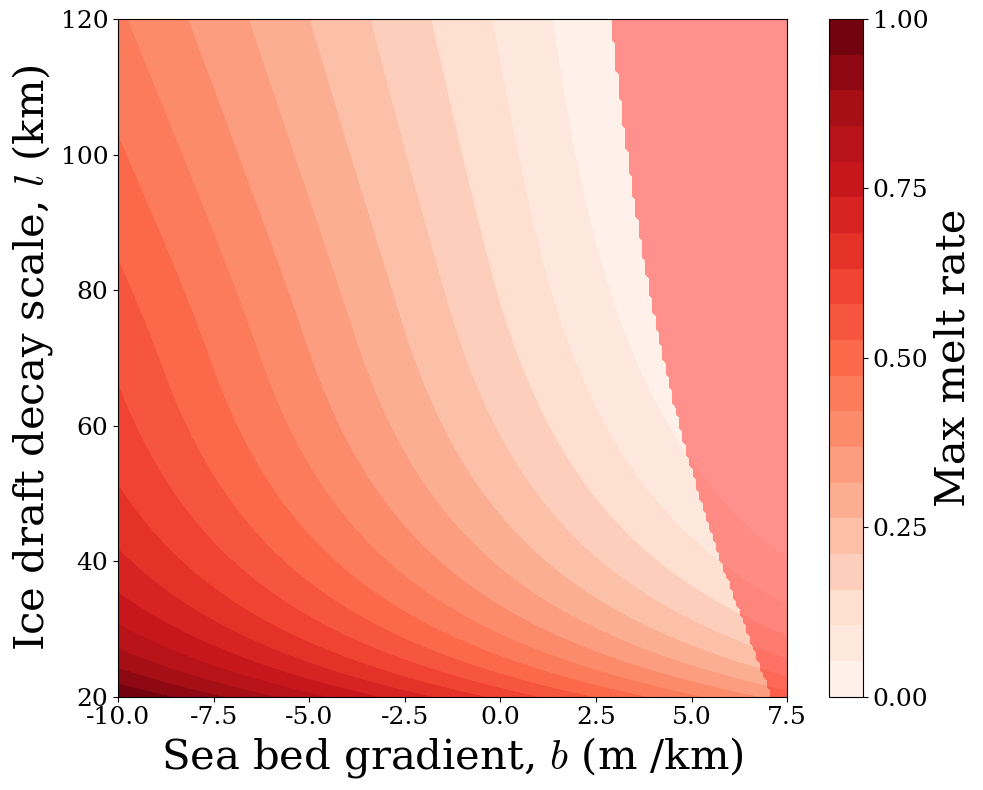

In [209]:

l_values = np.linspace(20000, 120000, 200)  
D_f_values = np.linspace(150, 1200, 200)      
                                      

H_gl = 600
H_f = 150
beta = 2.8
T2 = 1
W = 100000
L = 60000

delta_D = -D_f_values + H_gl

max_melt_value = np.zeros((len(l_values), len(D_f_values)))

delta_D = H_gl-D_f_values
D_f_grid, l_grid = np.meshgrid(D_f_values, l_values)
H_end_grid = H_f + (H_gl - H_f) * np.exp(-L / l_grid)  

mask = np.zeros((len(l_values), len(D_f_values)))

for i, l in enumerate(l_values):
    H = H_f + (H_gl - H_f) * np.exp(-y_vals / l)
    for j, D_f in enumerate(D_f_values):
        D = H_gl + (D_f - H_gl) * y_vals / L
        mask[i, j] = np.min(D - H)  # negative if D < H anywhere

for i, l in enumerate(l_values):
    for j, D_f in enumerate(D_f_values):
        max_melt_value[i, j] = m_linD_expH_max_value(y_vals, H_gl, H_f, D_f, l, beta, T2, W)



fig, ax = plt.subplots(figsize=(10, 8))
max_melt_norm = max_melt_value / np.max(max_melt_value)

im = ax.contourf(delta_D, l_values/1000, max_melt_norm, levels=np.linspace(0, 1, 20), cmap='Reds')
#  Red overlay where D_f > H[-1]
ax.contourf(delta_D, l_values/1000, mask, levels=[-np.inf, -1e-10], colors=['red'], alpha=0.4)
ax.contour(delta_D, l_values/1000, mask, levels=[0], colors='red', linewidths=1.5)


cbar = plt.colorbar(im, ax=ax, ticks=np.linspace(0, 1, 5))
cbar.set_label('Max melt rate', fontsize=30)

cbar.ax.tick_params(labelsize=18, color='black', labelcolor='black')
L_km = L / 1000  # 60 km
L_km = L / 1000  # 60

tick_gradients = np.array([-10,-7.5,-5, -2.5, 0, 2.5, 5, 7.5]) 
tick_positions = tick_gradients * L_km             

ax.set_xticks(tick_positions)
ax.set_xticklabels([str(g) for g in tick_gradients])
ax.set_xlabel('Sea bed gradient, $b$ (m /km)', fontsize=30)
ax.tick_params(axis='both', labelsize=18)
ax.set_ylabel('Ice draft decay scale, $l$ (km)', fontsize=30)
plt.tight_layout()

plt.savefig('max_melt_value_heatmap.pdf', bbox_inches='tight', pad_inches=0.1)
plt.show()


In [210]:
import numpy as np
from scipy.integrate import quad

def compute_m(coeffs, H_f, delta_H, y_f, A, T2, l, beta):
    """
    Compute m(y) = (1/A) * ∫₀^y_f (p5(x) - H(x)) * H'(x) dx
    
    Parameters:
    coeffs : list or array
        Coefficients [a0, a1, a2, a3, a4, a5] of the 5th-order polynomial p5(x)
    H_coeffs : tuple
        Parameters of H(x) = B * exp(-k x), (B, k)
    y_f : float
        Upper limit of integration
    A : float
        Denominator scaling factor
    """

    

    # Polynomial (highest order first)
    def p5(y):
        return np.polyval(coeffs, y)

    # Exponential thickness
    def H(y):
        return H_f + delta_H * np.exp(-y / l)

    # Derivative
    def H_prime(y):
        return -(delta_H / l) * np.exp(-y / l)

    # Integrand
    def integrand(y):
        return (p5(y) - H(y)) * H_prime(y)

    integral, _ = quad(integrand, 0, y_f)

    
     
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    L = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974
    k = (T2-Tf)*g*(rho_2-rho_1)*C_p/(rho_i*L*f*(beta+1))
    
    # Divide by A
    return k*integral / A



## Melt for exponential H and quadratic D ##

In [211]:
def exp_H(y, L):
    H_gl = 600
    H_front = 300
    
    return H_front + (H_gl - H_front) * np.exp(-y / L)

In [212]:


def plot_m_vs_y_quad_D(H, L, y_values, beta, b, c, T2, W, ax=None):
    """
    Takes a function H(y) and plots m(y) = dH/dy against y.
    
    Parameters:
    H: a function that takes y as input
    L: characteristic length scale for the exponential decay
    y_values: array of y values to evaluate
    y_values: array of y values to evaluate
    Parameters:
    H: slope of the ice base
    y_values: array of y values
    calculation_func: function to convert H to melt rate in m/s
    T2: temperature of the lower layer
    D: depth of the sea floor
    beta: ratio of h1 to h2

    """
     
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    Lf = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974 
    alpha = 0.094

    g_prime = g*(rho_2-rho_1)/rho_2
    k = alpha*C_p*(T2-Tf)*g_prime*rho_2/(rho_i*Lf*f*(beta+1))
    # Calculate H(y)
    H_values = H(y_values, L)
    D_values = D_quadratic(y_values, b, c)
    # Calculate derivative of H at each y value
    H_prime = np.gradient(H_values, y_values)
    m_values = -H_prime*(D_values-H_values)*k/W # in m/s and magnitude of transport used
    m_values_year = m_values*(60*60*24*365)

    print(f"k = {k}")
    print(f"H_prime max = {np.max(H_prime)}")
    print(f"(D-H) max = {np.max(D-H_values)}")
    print(f"W = {W}")
    print(f"m_values max (m/s) = {np.max(m_values)}")
    print(f"m_values max (m/yr) = {np.max(m_values_year)}")


    if ax is None:
        plt.figure(figsize=(8, 6))
        ax = plt.gca()
    
    ax.plot(y_values/1000, m_values_year)
    ax.set_xlabel('Distance from grounding line (km)')
    ax.set_ylabel('Melt rate (m/yr)')
    ax.set_title(f"Melt rate for a cavity")
    ax.grid(True)

k = 0.01824359348799803
H_prime max = -0.00017671455788522992
(D-H) max = 892.9446762431973
W = 100000
m_values max (m/s) = 3.798501354098087e-07
m_values max (m/yr) = 11.978953870283727


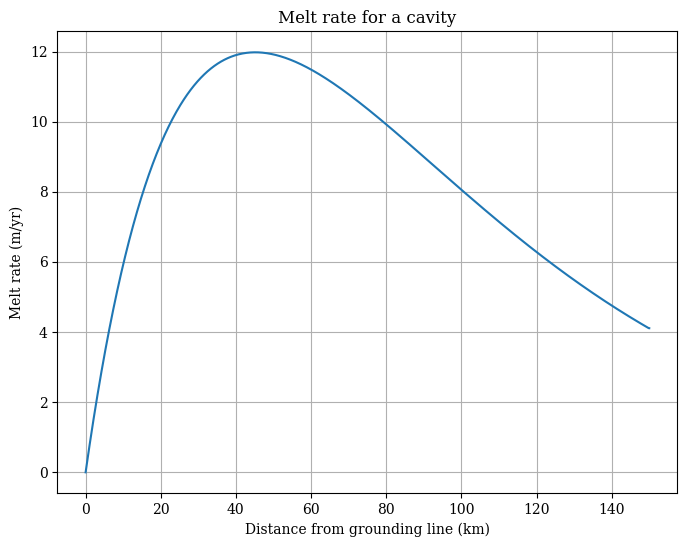

In [213]:
y_vals = np.linspace(0, 150000, 1000)
plot_m_vs_y_quad_D(exp_H, 40000, y_vals, 2.8, 0.01, 0.0000001, 1, 100000)

24 valid parameter combinations (D > H everywhere)



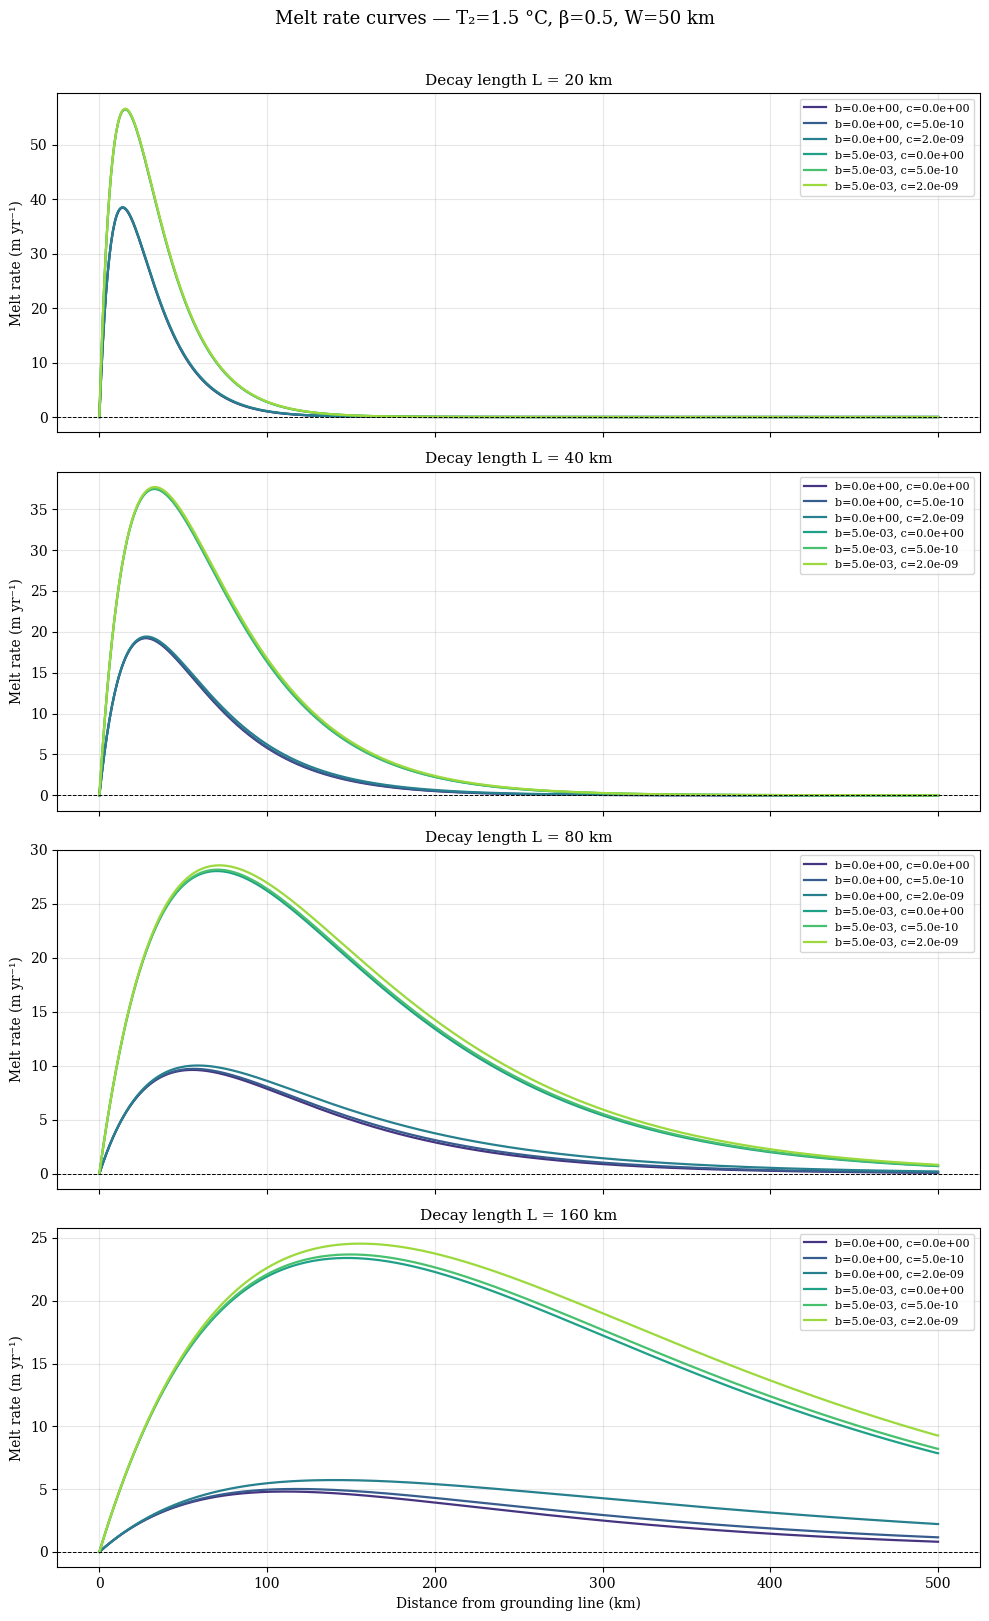

Saved → melt_curves.png


In [214]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

Tf    = -1.9
g     = 9.8
rho_1 = 1027.55
rho_2 = 1027.75
rho_i = 917
Lf    = 3.34e5
f     = 1e-4
C_p   = 3974
alpha = 0.094
g_prime = g * (rho_2 - rho_1) / rho_2

def exp_H(y, L):
    H_gl, H_front = 600, 300
    return H_front + (H_gl - H_front) * np.exp(-y / L)

def D_quadratic(y_vals, b, c):
    return 600 + b * y_vals + c * y_vals**2

L_values = [20e3, 40e3, 80e3, 160e3]          # decay lengths  (m)
b_values = [-5e-3, 0.0,  5e-3]                  # linear floor slope
c_values = [ 0.0,  5e-10, 2e-9]                 # quadratic floor curvature

T2   = 1.5    
beta = 0.5
W    = 50e3   # channel width  (m)

y_values = np.linspace(0, 500e3, 1000)

# ── Build valid  combos where D > H everywhere ────────────────────
valid_combos = []
for L in L_values:
    H_vals = exp_H(y_values, L)
    for b in b_values:
        for c in c_values:
            D_vals = D_quadratic(y_values, b, c)
            if np.all(D_vals + 1e-10 > H_vals):
                valid_combos.append((L, b, c))

print(f"{len(valid_combos)} valid parameter combinations (D > H everywhere)\n")

fig, axes = plt.subplots(
    len(L_values), 1,
    figsize=(10, 4 * len(L_values)),
    sharex=True
)

for ax, L in zip(axes, L_values):
    combos_for_L = [(b, c) for (Lc, b, c) in valid_combos if Lc == L]
    if not combos_for_L:
        ax.set_title(f"L = {L/1e3:.0f} km  (no valid D > H combos)")
        continue

    colors = cm.viridis(np.linspace(0.15, 0.85, len(combos_for_L)))
    H_vals = exp_H(y_values, L)

    for (b, c), col in zip(combos_for_L, colors):
        D_vals   = D_quadratic(y_values, b, c)
        k        = alpha * C_p * (T2 - Tf) * g_prime * rho_2 / (rho_i * Lf * f * (beta + 1))
        H_prime  = np.gradient(H_vals, y_values)
        m_vals   = -H_prime * (D_vals - H_vals) * k / W
        m_yr     = m_vals * 60 * 60 * 24 * 365
        label    = f"b={b:.1e}, c={c:.1e}"
        ax.plot(y_values / 1e3, m_yr, color=col, label=label, linewidth=1.6)

    ax.set_title(f"Decay length L = {L/1e3:.0f} km", fontsize=11)
    ax.set_ylabel("Melt rate (m yr⁻¹)")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color="k", linewidth=0.7, linestyle="--")

axes[-1].set_xlabel("Distance from grounding line (km)")
fig.suptitle(
    f"Melt rate curves — T₂={T2} °C, β={beta}, W={W/1e3:.0f} km",
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig("melt_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → melt_curves.png")

Gradient of peak melt rate with respect to b (m/yr per 10⁻³) for l=160 km: 3.16
Overall slope: 3.57 m/yr per 10⁻³
[-0.15384615  0.92307692  2.        ]


/var/folders/dp/bxjb_th907g0tlby49jsjkhr0000gn/T/ipykernel_67094/3348242032.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


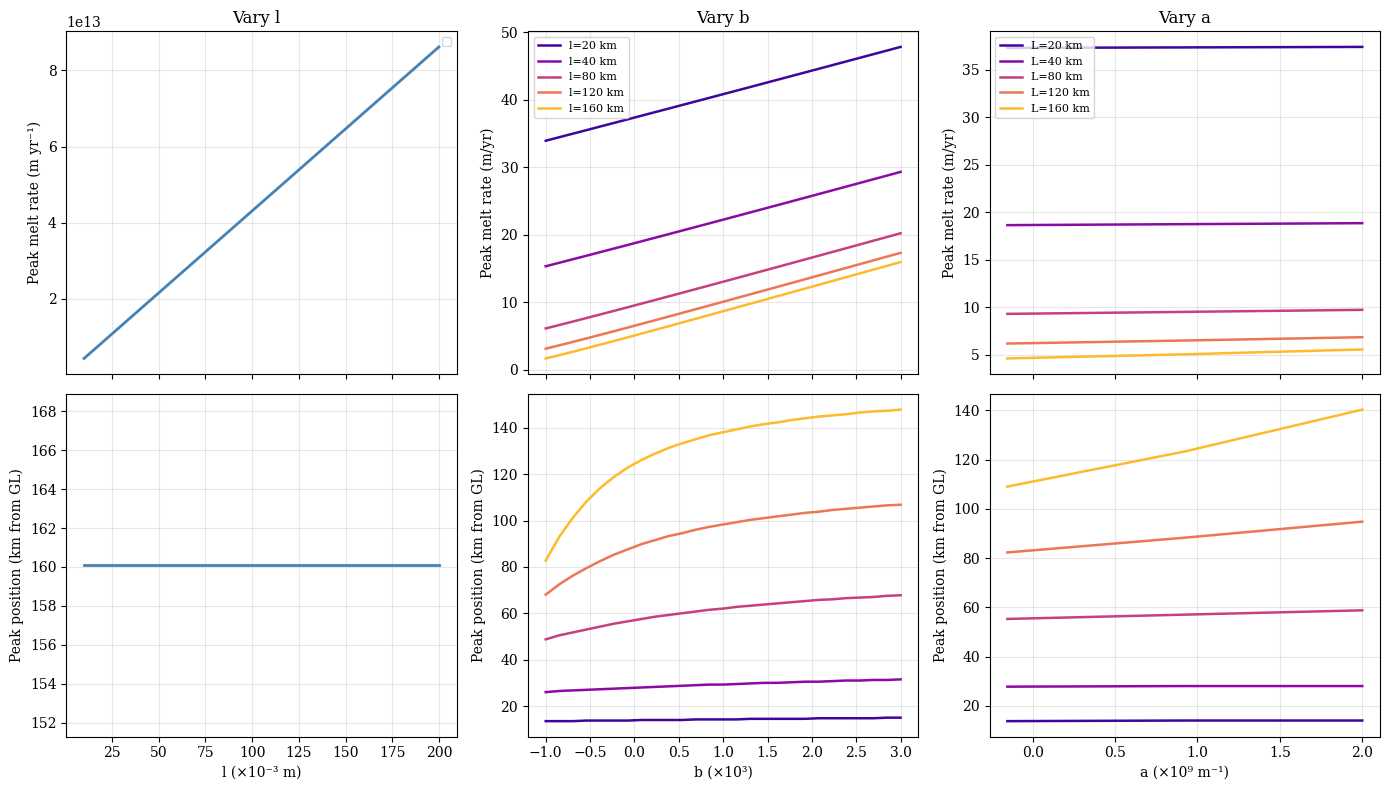

In [215]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

Tf    = -1.8;  g = 9.8
rho_1 = 1027.55;  rho_2 = 1027.75;  rho_i = 917
Lf    = 3.34e5;   f = 1e-4;  C_p = 3974;  alpha = 0.094
g_prime = g * (rho_2 - rho_1) / rho_2
T2 = 1.5;  beta = 0.5;  W = 50e3
k = alpha * C_p * (T2 - Tf) * g_prime * rho_2 / (rho_i * Lf * f * (beta + 1))

y = np.linspace(0, 500e3, 2000)

def exp_H(y, L):
    return 300 + 300 * np.exp(-y / L)

def D_quad(y, b, c):
    return 600 + b * y + c * y**2

def compute_peak(L, b, c):
    H = exp_H(y, L);  D = D_quad(y, b, c)
    if not np.all(D[1:] >= H[1:]):
        return np.nan, np.nan
    m = -np.gradient(H, y) * (D - H) * k / W * 86400 * 365
    idx = np.argmax(m)
    return y[idx] / 1e3, m[idx]

L_vals = np.linspace(10e3,  200e3, 40)
b_vals = np.linspace(-3e-3,  3e-3, 40)
c_vals = np.linspace(-4e-8,      2e-9, 40)

L0, b0, c0 = 80e3, 0.0, 1e-9

def sweep(param, vals, L=L0, b=b0, c=c0):
    pos, amp = [], []
    for v in vals:
        if param == 'l': p, a = compute_peak(v, b, c)
        elif param == 'b': p, a = compute_peak(L, v, c)
        else:             p, a = compute_peak(L, b, v)
        pos.append(p);  amp.append(a)
    return np.array(pos), np.array(amp)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex='col')

# ── Column 0: vary L ─────────────────────────────────────────────────────────
pos_L, amp_L = sweep('L', L_vals)
valid = ~np.isnan(amp_L)

ax = axes[0, 0]
ax.plot(L_vals[valid]/1e3, amp_L[valid], color='steelblue', lw=2)
ax.set_ylabel('Peak melt rate (m yr⁻¹)')
ax.set_title('Vary l  ')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
ax.plot(L_vals[valid]/1e3, pos_L[valid], color='steelblue', lw=2)
ax.set_xlabel('l (×10⁻³ m)')
ax.set_ylabel('Peak position (km from GL)')
ax.grid(True, alpha=0.3)

# ── Column 1: vary b, for multiple fixed l ──────────────────────────────────
L_lines = [20e3, 40e3, 80e3, 120e3, 160e3]
colors_L = cm.plasma(np.linspace(0.1, 0.85, len(L_lines)))

for ax_row, metric in zip([axes[0,1], axes[1,1]], ['amp', 'pos']):
    for L_fix, col in zip(L_lines, colors_L):
        pos_b, amp_b = sweep('b', b_vals, L=L_fix)
        valid = ~np.isnan(amp_b)
        data = amp_b if metric == 'amp' else pos_b
        ax_row.plot(b_vals[valid]*1e3, data[valid],
                    color=col, lw=1.8, label=f'l={L_fix/1e3:.0f} km')
    ax_row.grid(True, alpha=0.3)
gradient_peak = np.gradient(amp_b[valid], b_vals[valid]*1e3)
print(f"Gradient of peak melt rate with respect to b (m/yr per 10⁻³) for l={L_fix/1e3:.0f} km: {gradient_peak[0]:.2f}")
slope = (amp_b[valid][-1] - amp_b[valid][0]) / (b_vals[valid][-1] - b_vals[valid][0]) * 1e-3
print(f"Overall slope: {slope:.2f} m/yr per 10⁻³")
axes[0,1].set_title('Vary b')
axes[0,1].set_ylabel('Peak melt rate (m/yr)')
axes[0,1].legend(fontsize=8, loc='upper left')
axes[1,1].set_xlabel('b (×10³)')
axes[1,1].set_ylabel('Peak position (km from GL)')

# ── Column 2: vary c, for multiple fixed l ──────────────────────────────────
for ax_row, metric in zip([axes[0,2], axes[1,2]], ['amp', 'pos']):
    for L_fix, col in zip(L_lines, colors_L):
        pos_c, amp_c = sweep('a', c_vals, L=L_fix)
        valid = ~np.isnan(amp_c)
        data = amp_c if metric == 'amp' else pos_c
        ax_row.plot(c_vals[valid]*1e9, data[valid],
                    color=col, lw=1.8, label=f'L={L_fix/1e3:.0f} km')
    ax_row.grid(True, alpha=0.3)
print(c_vals[valid]*1e9)
axes[0,2].set_title('Vary a')
axes[0,2].set_ylabel('Peak melt rate (m/yr)')
axes[0,2].legend(fontsize=8, loc='upper left')
axes[1,2].set_xlabel('a (×10⁹ m⁻¹)')
axes[1,2].set_ylabel('Peak position (km from GL)')

fig.tight_layout()
fig.savefig('peak_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

In [216]:

Tf    = -1.8;  g = 9.8
rho_1 = 1027.55;  rho_2 = 1027.75;  rho_i = 917
Lf    = 3.34e5;   f = 1e-4;  C_p = 3974;  alpha = 0.094
g_prime = g * (rho_2 - rho_1) / rho_2
T2 = 1.5;  beta = 0.5;  W = 50e3
k = alpha * C_p * (T2 - Tf) * g_prime * rho_2 / (rho_i * Lf * f * (beta + 1))

y = np.linspace(0, 500e3, 2000)

def exp_H(y, L):
    return 300 + 300 * np.exp(-y / L)

def D_quad(y, b, c):
    return 600 + b * y + c * y**2

def compute_peak(L, b, c):
    H = exp_H(y, L);  D = D_quad(y, b, c)
    if not np.all(D[1:] >= H[1:]):
        return np.nan, np.nan
    m = -np.gradient(H, y) * (D - H) * k / W * 86400 * 365
    idx = np.argmax(m)
    return y[idx] / 1e3, m[idx]

# ── Parameter ranges ────────────────────────────────────────────────────────
L_vals = np.linspace(10e3,  200e3, 40)
b_vals = np.linspace(-3e-3,  3e-3, 40)
c_vals = np.linspace(-4e-8,      2e-9, 40)

# Reference / default values
L0, b0, c0 = 80e3, 0.0, 1e-9

# ── Sweep each parameter independently ──────────────────────────────────────
def sweep(param, vals, L=L0, b=b0, c=c0):
    pos, amp = [], []
    for v in vals:
        if param == 'l': p, a = compute_peak(v, b, c)
        elif param == 'b': p, a = compute_peak(L, v, c)
        else:             p, a = compute_peak(L, b, v)
        pos.append(p);  amp.append(a)
    return np.array(pos), np.array(amp)

L_lines  = [20e3, 40e3, 80e3, 120e3, 160e3]
colors_L = cm.plasma(np.linspace(0.1, 0.85, len(L_lines)))

# ── Figure 1: vary L ─────────────────────────────────────────────────────────
pos_L, amp_L = sweep('l', L_vals)
valid = ~np.isnan(amp_L)

fig, axes = plt.subplots(2, 1, figsize=(5, 7), sharex=True)

axes[0].plot(L_vals[valid]/1e3, amp_L[valid], color='steelblue', lw=2)
axes[0].set_ylabel('Peak melt rate (m/yr)', fontsize=18)

axes[0].grid(True, alpha=0.3)

axes[1].plot(L_vals[valid]/1e3, pos_L[valid], color='steelblue', lw=2)
axes[1].set_xlabel('$l$ (km)', fontsize=18)
axes[1].set_ylabel('Peak position (km)', fontsize=18)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivity_l.pdf', bbox_inches='tight', pad_inches=0.05)
plt.close()

# ── Figure 2: vary b ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(5, 7), sharex=True)

for L_fix, col in zip(L_lines, colors_L):
    pos_b, amp_b = sweep('b', b_vals, L=L_fix)
    valid = ~np.isnan(amp_b)
    axes[0].plot(b_vals[valid]*1e3, amp_b[valid], color=col, lw=1.8, label=f'$l$={L_fix/1e3:.0f} km')
    axes[1].plot(b_vals[valid]*1e3, pos_b[valid], color=col, lw=1.8, label=f'$l$={L_fix/1e3:.0f} km')

axes[0].set_ylabel('Peak melt rate (m/yr)', fontsize=18)
axes[0].set_xlabel('$b$  (×$10^3$)', fontsize=18)
axes[0].legend(fontsize=14, loc='upper left')
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('$b$  (×$10^3$)', fontsize=18)
axes[1].set_ylabel('Peak position (km)', fontsize=18)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivity_b.pdf', bbox_inches='tight', pad_inches=0.05)
plt.close()

# ── Figure 3: vary c ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(5, 7), sharex=True)

for L_fix, col in zip(L_lines, colors_L):
    pos_c, amp_c = sweep('a', c_vals, L=L_fix)
    valid = ~np.isnan(amp_c)
    axes[0].plot(c_vals[valid]*1e9, amp_c[valid], color=col, lw=1.8, label=f'$l$={L_fix/1e3:.0f} km')
    axes[1].plot(c_vals[valid]*1e9, pos_c[valid], color=col, lw=1.8, label=f'$l$={L_fix/1e3:.0f} km')

axes[0].set_ylabel('Peak melt rate (m/yr)', fontsize=18)

axes[0].legend(fontsize=14, loc='upper left')
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('$a$  (×$10^9$ m$^{-1}$)', fontsize=18)
axes[1].set_ylabel('Peak position (km)', fontsize=18)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivity_c.pdf', bbox_inches='tight', pad_inches=0.05)
plt.close()

In [217]:
import numpy as np
import matplotlib.pyplot as plt

# ── Okabe-Ito Colorblind-Friendly Palette ───────────────────────────────────
okabe_ito = [
    '#E69F00', # Orange
    '#56B4E9', # Sky Blue
    '#009E73', # Bluish Green
    '#F0E442', # Yellow
    '#0072B2', # Blue
    '#D55E00', # Vermillion
    '#CC79A7', # Reddish Purple
    '#000000'  # Black
]


Tf    = -1.8
g = 9.8
rho_1 = 1027.55
rho_2 = 1027.75  
rho_i = 917
Lf    = 3.34e5  
f = 1e-4
C_p = 3974
alpha = 0.094
g_prime = g * (rho_2 - rho_1) / rho_2
T2 = 1.5
beta = 0.5
W = 50e3
k = alpha * C_p * (T2 - Tf) * g_prime * rho_2 / (rho_i * Lf * f * (beta + 1))

y = np.linspace(0, 500e3, 2000)

def exp_H(y, L):
    return 300 + 300 * np.exp(-y / L)

def D_quad(y, b, c):
    return 600 + b * y + c * y**2

def compute_peak(L, b, c):
    H = exp_H(y, L);  D = D_quad(y, b, c)
    if not np.all(D[1:] >= H[1:]):
        return np.nan, np.nan
    m = -np.gradient(H, y) * (D - H) * k / W * 86400 * 365
    idx = np.argmax(m)
    return y[idx] / 1e3, m[idx]

# ── Parameter ranges ────────────────────────────────────────────────────────
L_vals = np.linspace(10e3,  200e3, 40)
b_vals = np.linspace(-3e-3,  3e-3, 40)
c_vals = np.linspace(-4e-8,      2e-9, 40)

# Reference  values
L0, b0, c0 = 80e3, 0.0, 1e-9

# ── Sweep each parameter independently ──────────────────────────────────────
def sweep(param, vals, L=L0, b=b0, c=c0):
    pos, amp = [], []
    for v in vals:
        if param == 'l': p, a = compute_peak(v, b, c)
        elif param == 'b': p, a = compute_peak(L, v, c)
        else:              p, a = compute_peak(L, b, v)
        pos.append(p);  amp.append(a)
    return np.array(pos), np.array(amp)

L_lines  = [20e3, 40e3, 80e3, 120e3, 160e3]

# Apply the accessible colors to the 5 lines
colors_L = okabe_ito[:len(L_lines)]

# ── Figure 1: vary L ─────────────────────────────────────────────────────────
pos_L, amp_L = sweep('l', L_vals)
valid = ~np.isnan(amp_L)

fig, axes = plt.subplots(2, 1, figsize=(5, 7), sharex=True)

axes[0].plot(L_vals[valid]/1e3, amp_L[valid], color=okabe_ito[4], lw=2)
axes[0].set_ylabel('Peak melt rate (m/yr)', fontsize=18)
axes[0].grid(True, alpha=0.3)

axes[1].plot(L_vals[valid]/1e3, pos_L[valid], color=okabe_ito[4], lw=2)
axes[1].set_xlabel(r'$l$ (km)', fontsize=18)
axes[1].set_ylabel('Peak position (km)', fontsize=18)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivity_l.pdf', bbox_inches='tight', pad_inches=0.05)
plt.close()

# ── Figure 2: vary b ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(5, 7), sharex=True)

for L_fix, col in zip(L_lines, colors_L):
    pos_b, amp_b = sweep('b', b_vals, L=L_fix)
    valid = ~np.isnan(amp_b)
    axes[0].plot(b_vals[valid]*1e3, amp_b[valid], color=col, lw=1.8, label=rf'$l$={L_fix/1e3:.0f} km')
    axes[1].plot(b_vals[valid]*1e3, pos_b[valid], color=col, lw=1.8, label=rf'$l$={L_fix/1e3:.0f} km')

axes[0].set_ylabel('Peak melt rate (m/yr)', fontsize=18)
axes[0].legend(fontsize=14, loc='upper left')
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel(r'$b$  ($\times 10^3$)', fontsize=18)
axes[1].set_ylabel('Peak position (km)', fontsize=18)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivity_b.pdf', bbox_inches='tight', pad_inches=0.05)
plt.close()

# ── Figure 3: vary c ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(5, 7), sharex=True)

for L_fix, col in zip(L_lines, colors_L):
    pos_c, amp_c = sweep('a', c_vals, L=L_fix)
    valid = ~np.isnan(amp_c)
    axes[0].plot(c_vals[valid]*1e9, amp_c[valid], color=col, lw=1.8, label=rf'$l$={L_fix/1e3:.0f} km')
    axes[1].plot(c_vals[valid]*1e9, pos_c[valid], color=col, lw=1.8, label=rf'$l$={L_fix/1e3:.0f} km')

axes[0].set_ylabel('Peak melt rate (m/yr)', fontsize=18)
axes[0].legend(fontsize=14, loc='upper left')
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel(r'$a$  ($\times 10^9$ m$^{-1}$)', fontsize=18)
axes[1].set_ylabel('Peak position (km)', fontsize=18)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivity_c.pdf', bbox_inches='tight', pad_inches=0.05)
plt.close()

D at y=500 km:
  Vary b (c=c0):
    b=-3.0e-03: D = -650 m
    b=-4.0e-04: D = 650 m
    b=0.0e+00: D = 850 m
    b=5.0e-04: D = 1100 m
    b=3.0e-03: D = 2350 m  <-- unrealistic
  Vary c (b=0):
    c=-1.0e-09: D = 350 m
    c=1.0e-12: D = 600 m
    c=1.0e-09: D = 850 m
    c=2.0e-09: D = 1100 m


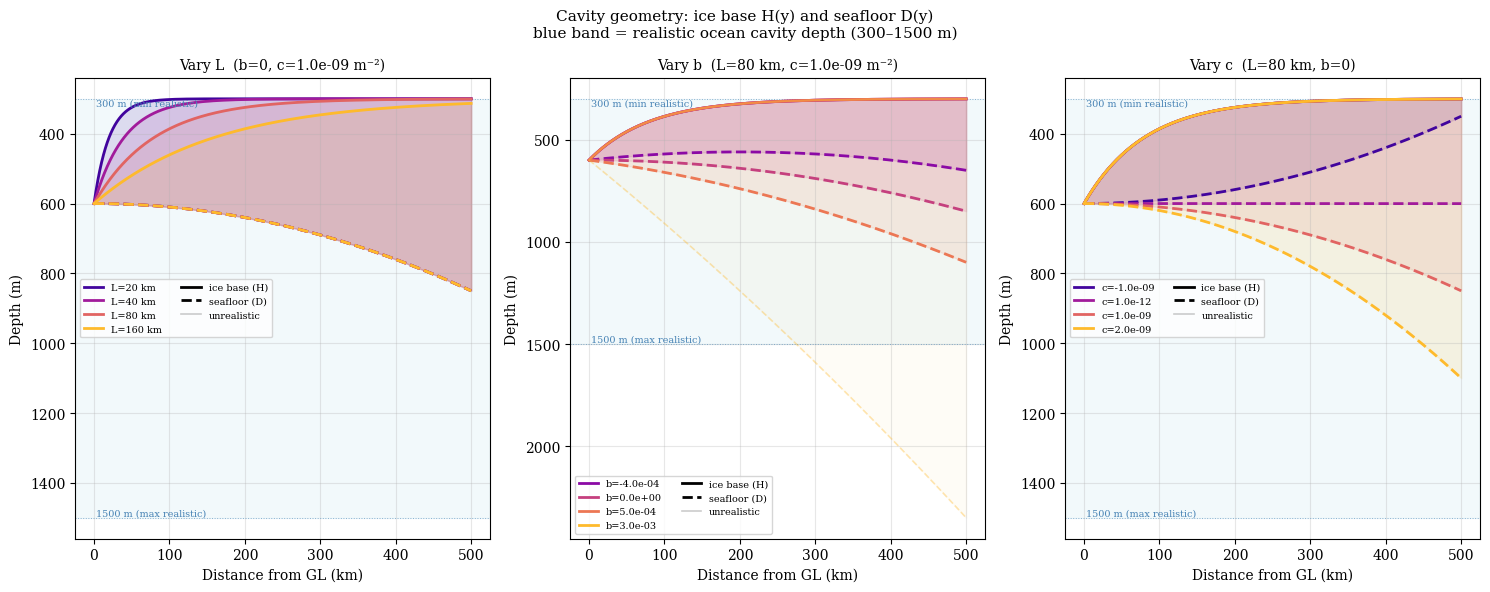

In [218]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def exp_H(y, L):
    return 300 + 300 * np.exp(-y / L)

def D_quad(y, b, c):
    return 600 + b * y + c * y**2

y = np.linspace(0, 500e3, 2000)

L_vals = [20e3, 40e3, 80e3, 160e3]
b_vals = [-3e-3, -4e-4, 0.0, 5e-4, 3e-3]
c_vals = [-1e-9, 1e-12, 1e-9, 2e-9]
b0, c0, L0 = 0.0, 1e-9, 80e3

colors5 = cm.plasma(np.linspace(0.1, 0.85, len(b_vals)))
colors4 = cm.plasma(np.linspace(0.1, 0.85, len(c_vals)))

print("D at y=500 km:")
print("  Vary b (c=c0):")
for b in b_vals:
    d = D_quad(500e3, b, c0)
    flag = "  <-- unrealistic" if d > 1500 else ""
    print(f"    b={b:.1e}: D = {d:.0f} m{flag}")
print("  Vary c (b=0):")
for c in c_vals:
    d = D_quad(500e3, 0, c)
    flag = "  <-- unrealistic" if d > 1500 else ""
    print(f"    c={c:.1e}: D = {d:.0f} m{flag}")

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
fig.suptitle('Cavity geometry: ice base H(y) and seafloor D(y)\n'
             'blue band = realistic ocean cavity depth (300–1500 m)', fontsize=11)

def plot_cavity(ax, H_cases, D_cases, labels, colors, title):
    ax.axhspan(300, 1500, color='lightblue', alpha=0.15, zorder=0)
    ax.axhline(300,  color='steelblue', lw=0.7, ls=':', alpha=0.6)
    ax.axhline(1500, color='steelblue', lw=0.7, ls=':', alpha=0.6)
    ax.text(2, 300,  '300 m (min realistic)',  fontsize=7,
            color='steelblue', va='top')
    ax.text(2, 1500, '1500 m (max realistic)', fontsize=7,
            color='steelblue', va='bottom')

    for H, D, label, color in zip(H_cases, D_cases, labels, colors):
        if not np.all(D[1:] >= H[1:]):
            continue
        d_max = np.max(D)
        unrealistic = d_max > 1500
        lw    = 1.2 if unrealistic else 2.0
        alpha = 0.35 if unrealistic else 1.0

        ax.plot(y/1e3, H, color=color, lw=lw, alpha=alpha)
        ax.plot(y/1e3, D, color=color, lw=lw, alpha=alpha, ls='--')
        ax.fill_between(y/1e3, H, D, color=color,
                        alpha=0.04 if unrealistic else 0.12)

    for label, color in zip(labels, colors):
        ax.plot([], [], color=color, lw=2, label=label)
    ax.plot([], [], color='k', lw=2,       label='ice base (H)')
    ax.plot([], [], color='k', lw=2, ls='--', label='seafloor (D)')
    ax.plot([], [], color='gray', lw=1.2, alpha=0.4, label='unrealistic')

    ax.set_xlabel('Distance from GL (km)')
    ax.set_ylabel('Depth (m)')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3)

    ax.invert_yaxis()

# Panel 0: vary L
plot_cavity(axes[0],
            [exp_H(y, L) for L in L_vals],
            [D_quad(y, b0, c0) for _ in L_vals],
            [f'L={L/1e3:.0f} km' for L in L_vals],
            colors4,
            f'Vary L  (b=0, c={c0:.1e} m⁻²)')

# Panel 1: vary b
H_list = [exp_H(y, L0) for _ in b_vals]
D_list = [D_quad(y, b, c0) for b in b_vals]
valid  = [np.all(D[1:] >= H[1:]) for H, D in zip(H_list, D_list)]
plot_cavity(axes[1],
            [H for H, v in zip(H_list, valid) if v],
            [D for D, v in zip(D_list, valid) if v],
            [f'b={b:.1e}' for b, v in zip(b_vals, valid) if v],
            [c for c, v in zip(colors5, valid) if v],
            f'Vary b  (L={L0/1e3:.0f} km, c={c0:.1e} m⁻²)')

# Panel 2: vary c
H_list = [exp_H(y, L0) for _ in c_vals]
D_list = [D_quad(y, b0, c) for c in c_vals]
valid  = [np.all(D[1:] >= H[1:]) for H, D in zip(H_list, D_list)]
plot_cavity(axes[2],
            [H for H, v in zip(H_list, valid) if v],
            [D for D, v in zip(D_list, valid) if v],
            [f'c={c:.1e}' for c, v in zip(c_vals, valid) if v],
            [col for col, v in zip(colors4, valid) if v],
            f'Vary c  (L={L0/1e3:.0f} km, b=0)')

fig.tight_layout()
fig.savefig('cavity_geometry_annotated.png', dpi=150, bbox_inches='tight')
plt.show()

In [219]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

def plot_m_vs_y_panel( y_values):
    """
    Takes a function H(y) and plots m(y) = dH/dy against y.
    
    Parameters:
    H: a function that takes y as input
    y_values: array of y values to evaluate
    Parameters:
    H: slope of the ice base
    y_values: array of y values
    calculation_func: function to convert H to melt rate in m/s
    T2: temperature of the lower layer
    D: depth of the sea floor
    beta: ratio of h1 to h2

    """
     
    T2 = 1.5
    W=150000
    Tf = -1.9 # celcius
    g = 9.8 # m/s^2
    rho_1 = 1027.55 #kg/m^3
    rho_2 = 1027.75 #kg/m^3
    rho_i = 917 #kg/m^3
    Lf = 3.34*10**5 #J/kg
    f = 10**(-4) # s^{-1}
    C_p = 3974 
    alpha = 0.319 # using average alpha/(beta+1) from F&S matching

    g_prime = g*(rho_2-rho_1)/rho_2
    k = alpha*C_p*(T2-Tf)*g_prime*rho_2/(rho_i*Lf*f)
    # Calculate H(y)
    L = 30000
    l = 150000
    exp_H= 200 + (H_gl - 200) * np.exp(-y_values / (L))
    lin_H = H_gl + (200-H_gl)*(y_values / l)
    sqrt_H = H_gl- (H_gl - 200) * ( np.sqrt(y_values / l))
    D_const = 600
    D_lin = 600 - 0.0005*y_values
    D_quad = 600 - 0.0005*y_values - 4e-9*y_values**2
    delta_H = H_gl - 200
    b = -0.0005
    c = -4e-9


    # Calculate derivative of H at each y value
    exp_H_prime = np.gradient(exp_H, y_values)
    exp_H_M = -(exp_H*(D_const-0.5*exp_H)-0.5*D_const**2)+(exp_H*(D_const-0.5*exp_H)-0.5*D_const**2)[0]
    exp_H_m = exp_H_prime*(D_const-exp_H)/W 
    exp_H_m_normalised = -exp_H_m * k *(60*60*24*365)
    exp_H_M_normalised = exp_H_M * k *(60*60*24*365)/1e12*917
    

    lin_H_prime = np.gradient(lin_H, y_values)
    lin_H_m = lin_H_prime*(D_const-lin_H)/W 
    lin_H_M = (lin_H*(D_const-0.5*lin_H)-0.5*D_const**2)
    lin_H_m_normalised = lin_H_m/lin_H_M[-1]*exp_H_M[-1]* k *(60*60*24*365) # normalise by max value for this curve
    lin_H_M_normalised = lin_H_M/lin_H_M[-1]*exp_H_M[-1]* k *(60*60*24*365)/1e12*917

    sqrt_H_prime = np.gradient(sqrt_H, y_values)
    sqrt_H_m = sqrt_H_prime*(D_const-sqrt_H)*k/W   
    sqrt_H_M = (sqrt_H*(D_const-0.5*sqrt_H)-0.5*D_const**2)*k
    sqrt_H_m_normalised = sqrt_H_m/sqrt_H_M[-1]*exp_H_M[-1]* k *(60*60*24*365) # normalise by max value for this curve
    sqrt_H_M_normalised = sqrt_H_M/sqrt_H_M[-1]*exp_H_M[-1]* k *(60*60*24*365)/1e12*917

    exp_H_lin_D_m = -exp_H_prime*(D_lin-exp_H)/W 
    exp_H_lin_D_M = (H_gl-200)/L*(L*delta_H/2*np.exp(-2*y_values/L)-b*L*(y_values+L)*np.exp(-y_values/L))-(H_gl-200)/L*(L*delta_H/2*np.exp(-2*y_values/L)-b*L*(y_values+L)*np.exp(-y_values/L))[0] # analytical solution for max value of this curve
    exp_H_lin_D_m_normalised = -exp_H_lin_D_m/exp_H_lin_D_M[-1]*exp_H_M[-1]* k *(60*60*24*365) # normalise by max value for this curve
    exp_H_lin_D_M_normalised = exp_H_lin_D_M/exp_H_lin_D_M[-1]*exp_H_M[-1]* k *(60*60*24*365)/1e12*917

    exp_H_quad_D_m = -exp_H_prime*(D_quad-exp_H)/W 
    exp_H_quad_D_M = (H_gl-200)/L*(L*delta_H/2*np.exp(-2*y_values/L)-c*L*(y_values**2+2*L*y_values+2*L**2)*np.exp(-y_values/L)-b*L*(y_values+L)*np.exp(-y_values/L))-(H_gl-200)/L*(L*delta_H/2*np.exp(-2*y_values/L)-c*L*(y_values**2+2*L*y_values+2*L**2)*np.exp(-y_values/L)-b*L*(y_values+L)*np.exp(-y_values/L))[0] # analytical solution for max value of this curve
    exp_H_quad_D_m_normalised = -exp_H_quad_D_m/exp_H_quad_D_M[-1]*exp_H_M[-1]* k *(60*60*24*365) # normalise by max value for this curve
    exp_H_quad_D_M_normalised = exp_H_quad_D_M/exp_H_quad_D_M[-1]*exp_H_M[-1]* k *(60*60*24*365)/1e12*917
    
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)

    COLORS = ['#3B0F70', '#8C2981', '#DE4968', '#FE9F6D', '#2D8B8B']

    curves_m = [sqrt_H_m_normalised, lin_H_m_normalised, exp_H_m_normalised,
                exp_H_lin_D_m_normalised, exp_H_quad_D_m_normalised]
    curves_M = [sqrt_H_M_normalised, lin_H_M_normalised, exp_H_M_normalised,
                exp_H_lin_D_M_normalised, exp_H_quad_D_M_normalised]
    panel_positions = [(0,0), (0,1), (0,2), (1,0), (1,1)]
    labels = [
        r'$\sqrt{y}$ base, const $D$',
        r'linear base, const $D$',
        r'exp base, const $D$',
        r'exp base, linear $D$',
        r'exp base, quadratic $D$',
    ]
    ykm = y_values / 1000
    H_curves = [-sqrt_H,- lin_H, -exp_H, -exp_H, -exp_H]
    D_curves = [-D_const, -D_const, -D_const, -D_lin, -D_quad]

   

    for (row, col), curve_m, H, D, label, color in zip(
            panel_positions, curves_m, H_curves, D_curves, labels, COLORS):
        ax = axes[row, col]
        ax.plot(ykm, curve_m, color=color, lw=1.8)
        ax.set_title(label, fontsize=18, pad=4)
        ax.set_xlabel('Distance from GL (km)', fontsize=18)
        ax.grid(True, alpha=0.25, linewidth=0.5)
        ax.tick_params(labelsize=14)

        ax2 = ax.twinx()
        ax2.plot(ykm, H, color='steelblue', lw=1.2, linestyle='--', alpha=0.7, label='H')
        ax2.plot(ykm, D if np.ndim(D) > 0 else np.full_like(ykm, D), 
                color='saddlebrown', lw=1.2, linestyle=':', alpha=0.7, label='D')
        ax2.fill_between(ykm, H, D, alpha=0.08, color='steelblue')  # shade the cavity
        ax2.set_ylabel(r'Depth (m)', fontsize=18, color='grey')
        ax2.tick_params(labelsize=14, colors='grey')
        ax2.spines['right'].set_color('grey')
        ax2.legend(fontsize=14, loc='upper right', framealpha=0.3)

    
            
    axes[0, 0].set_ylabel(r'$m(y)$  (m yr$^{-1}$)', fontsize=18)
    axes[1, 0].set_ylabel(r'$m(y)$  (m yr$^{-1}$)', fontsize=18)

    # ── overlaid M(y) panel (bottom-right) ───────────────────────────────────
    ax_M = axes[1, 2]
    for curve_M, label, color in zip(curves_M, labels, COLORS):
        ax_M.plot(ykm, curve_M, color=color, lw=1.8, label=label)

    ax_M.set_title(r'$M(y)$ — all cases', fontsize=18, pad=4)
    ax_M.set_xlabel('Distance from GL (km)', fontsize=18)
    ax_M.set_ylabel(r'$M(y)$  (Gt yr$^{-1}$)', fontsize=18)
    ax_M.legend(fontsize=14, framealpha=0.4, loc='lower right')
    ax_M.grid(True, alpha=0.25, linewidth=0.5)
    ax_M.tick_params(labelsize=14)
    for spine in ax_M.spines.values():
        spine.set_linewidth(0.6)

     

    fig.suptitle(
        r'Melt rate profiles for different $H(y)$ and $D(y)$ shapes',
        fontsize=12, fontweight='bold',
    )

    plt.show()

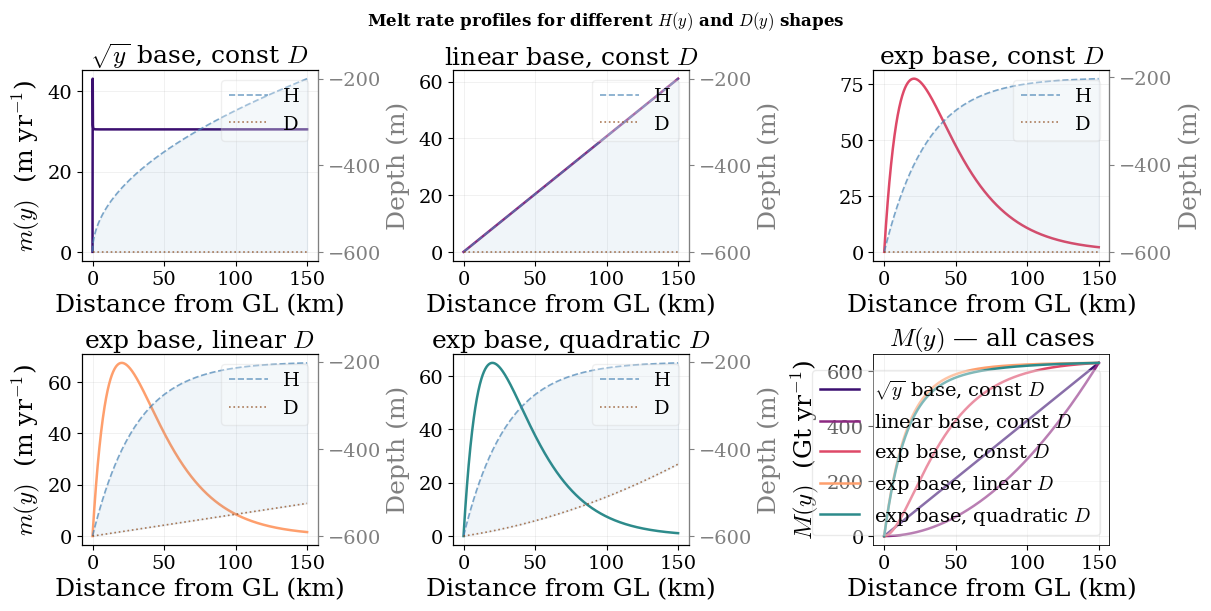

In [220]:
y_vals = np.linspace(0, 150000, 1000)
plot_m_vs_y_panel(y_vals)

In [221]:
import numpy as np
import matplotlib.pyplot as plt
import os
def plot_m_vs_y_panel(y_values):
    T2 = 1.5
    W = 150000
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.319

    g_prime = g * (rho_2 - rho_1) / rho_2
    k = alpha * C_p * (T2 - Tf) * g_prime * rho_2 / (rho_i * Lf * f)

    L = 30000
    l = 150000
    H_gl = 600

    exp_H   = 200 + (H_gl - 200) * np.exp(-y_values / L)
    lin_H   = H_gl + (200 - H_gl) * (y_values / l)
    sqrt_H  = H_gl - (H_gl - 200) * np.sqrt(y_values / l)
    D_const = 600
    D_lin   = 600 - 0.0005 * y_values
    D_quad  = 600 - 0.0005 * y_values - 4e-9 * y_values**2
    delta_H = H_gl - 200
    b = -0.0005
    c = -4e-9

    # ── Melt rates ────────────────────────────────────────────────────────────
    conv = k * 60 * 60 * 24 * 365  # m/s → m/yr factor

    exp_H_prime = np.gradient(exp_H, y_values)
    exp_H_M     = -(exp_H * (D_const - 0.5*exp_H) - 0.5*D_const**2) \
                  + (exp_H * (D_const - 0.5*exp_H) - 0.5*D_const**2)[0]
    exp_H_m_n   = -exp_H_prime * (D_const - exp_H) / W * conv
    exp_H_M_n   = exp_H_M * conv / 1e12 * 917
    ref_M_end   = exp_H_M_n[-1]   # reference for normalisation

    lin_H_prime = np.gradient(lin_H, y_values)
    lin_H_M     = lin_H * (D_const - 0.5*lin_H) - 0.5*D_const**2
    lin_H_m_n   = lin_H_prime * (D_const - lin_H) / W \
                  / lin_H_M[-1] * exp_H_M[-1] * conv
    lin_H_M_n   = lin_H_M / lin_H_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    sqrt_H_prime = np.gradient(sqrt_H, y_values)
    sqrt_H_M     = (sqrt_H * (D_const - 0.5*sqrt_H) - 0.5*D_const**2) * k
    sqrt_H_m_n   = sqrt_H_prime * (D_const - sqrt_H) * k / W \
                   / sqrt_H_M[-1] * exp_H_M[-1] * conv
    sqrt_H_M_n   = sqrt_H_M / sqrt_H_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    exp_H_lin_D_m  = -exp_H_prime * (D_lin - exp_H) / W
    exp_H_lin_D_M  = (H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                      - b*L*(y_values+L) * np.exp(-y_values/L)) \
                     - ((H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                      - b*L*(y_values+L) * np.exp(-y_values/L)))[0]
    exp_H_lin_D_m_n = -exp_H_lin_D_m / exp_H_lin_D_M[-1] * exp_H_M[-1] * conv
    exp_H_lin_D_M_n = exp_H_lin_D_M / exp_H_lin_D_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    exp_H_quad_D_m  = -exp_H_prime * (D_quad - exp_H) / W
    exp_H_quad_D_M  = (H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                       - c*L*(y_values**2 + 2*L*y_values + 2*L**2) * np.exp(-y_values/L)
                       - b*L*(y_values+L) * np.exp(-y_values/L)) \
                      - ((H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                       - c*L*(y_values**2 + 2*L*y_values + 2*L**2) * np.exp(-y_values/L)
                       - b*L*(y_values+L) * np.exp(-y_values/L)))[0]
    exp_H_quad_D_m_n = -exp_H_quad_D_m / exp_H_quad_D_M[-1] * exp_H_M[-1] * conv
    exp_H_quad_D_M_n = exp_H_quad_D_M / exp_H_quad_D_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    COLORS = ['#3B0F70', '#8C2981', '#DE4968', '#FE9F6D', '#2D8B8B']
    labels = [
        r'$H\sim \sqrt{y}$, $D=const$',
        r'$H\sim y$, $D=const$',
        r'$H\sim e^{-y}$, $D=const$',
        r'$H\sim e^{-y}$, $D\sim y$',
        r'$H\sim e^{-y}$, $D\sim y^2$',
    ]
    ykm      = y_values / 1000
    curves_m = [sqrt_H_m_n, lin_H_m_n, exp_H_m_n, exp_H_lin_D_m_n, exp_H_quad_D_m_n]
    curves_M = [sqrt_H_M_n, lin_H_M_n, exp_H_M_n, exp_H_lin_D_M_n, exp_H_quad_D_M_n]
    H_curves = [-sqrt_H, -lin_H, -exp_H, -exp_H, -exp_H]
    D_curves = [-D_const, -D_const, -D_const, -D_lin, -D_quad]

    filenames = [
        'sqrt_base_const_D',
        'lin_base_const_D',
        'exp_base_const_D',
        'exp_base_lin_D',
        'exp_base_quad_D',
    ]

    # ── 5 individual m(y) panels ──────────────────────────────────────────────
    for curve_m, H, D, label, color, fname in zip(
            curves_m, H_curves, D_curves, labels, COLORS, filenames):

        fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)

        ax.plot(ykm, curve_m, color=color, lw=1.8)
        
        ax.set_xlabel('Distance from GL (km)', fontsize=16)
        ax.set_ylabel(r'm(y)  (m/yr)', fontsize=16)
        ax.grid(True, alpha=0.25, linewidth=0.5)
        ax.tick_params(labelsize=14)

        ax2 = ax.twinx()
        D_plot = D if np.ndim(D) > 0 else np.full_like(ykm, D)
        ax2.plot(ykm, H,      color='steelblue',   lw=1.2, linestyle='--', alpha=0.7, label='$H$')
        ax2.plot(ykm, D_plot, color='saddlebrown',  lw=1.2, linestyle=':',  alpha=0.7, label='$D$')
        ax2.fill_between(ykm, H, D_plot, alpha=0.08, color='steelblue')
        ax2.set_ylabel(r'Depth (m)', fontsize=16, color='grey')
        ax2.tick_params(labelsize=14, colors='grey')
        ax2.spines['right'].set_color('grey')
        ax2.legend(fontsize=14, loc='upper right', framealpha=0.3)

        path = f'{fname}.pdf'
        fig.savefig(path, bbox_inches='tight')
        plt.close(fig)
        print(f'Saved {path}')

    # ── M(y) overlay panel ────────────────────────────────────────────────────
    fig, ax_M = plt.subplots(figsize=(4, 3), constrained_layout=True)

    for curve_M, label, color in zip(curves_M, labels, COLORS):
        ax_M.plot(ykm, curve_M, color=color, lw=1.8, label=label)

    
    ax_M.set_xlabel('Distance from GL (km)', fontsize=16)
    ax_M.set_ylabel(r'$M(y)$  (Gt yr$^{-1}$)', fontsize=16)
    ax_M.legend(fontsize=12, framealpha=0.4, loc='lower right')
    ax_M.grid(True, alpha=0.25, linewidth=0.5)
    ax_M.tick_params(labelsize=14)

    path = f'M_all_cases.pdf'
    fig.savefig(path, bbox_inches='tight')
    plt.close(fig)
    print(f'Saved {path}')

In [222]:

def plot_m_vs_y_panel(y_values):
    T2 = 1.5
    W = 150000
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.319

    g_prime = g * (rho_2 - rho_1) / rho_2
    k = alpha * C_p * (T2 - Tf) * g_prime * rho_2 / (rho_i * Lf * f)

    L = 30000
    l = 150000
    H_gl = 600

    exp_H   = 200 + (H_gl - 200) * np.exp(-y_values / L)
    lin_H   = H_gl + (200 - H_gl) * (y_values / l)
    sqrt_H  = H_gl - (H_gl - 200) * np.sqrt(y_values / l)
    D_const = 600
    D_lin   = 600 - 0.0005 * y_values
    D_quad  = 600 - 0.0005 * y_values - 4e-9 * y_values**2
    delta_H = H_gl - 200
    b = -0.0005
    c = -4e-9

    conv = k * 60 * 60 * 24 * 365  # m/s → m/yr factor

    exp_H_prime = np.gradient(exp_H, y_values)
    exp_H_M     = -(exp_H * (D_const - 0.5*exp_H) - 0.5*D_const**2) \
                  + (exp_H * (D_const - 0.5*exp_H) - 0.5*D_const**2)[0]
    exp_H_m_n   = -exp_H_prime * (D_const - exp_H) / W * conv
    exp_H_M_n   = exp_H_M * conv / 1e12 * 917
    ref_M_end   = exp_H_M_n[-1]   # reference for normalisation

    lin_H_prime = np.gradient(lin_H, y_values)
    lin_H_M     = lin_H * (D_const - 0.5*lin_H) - 0.5*D_const**2
    lin_H_m_n   = lin_H_prime * (D_const - lin_H) / W \
                  / lin_H_M[-1] * exp_H_M[-1] * conv
    lin_H_M_n   = lin_H_M / lin_H_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    sqrt_H_prime = np.gradient(sqrt_H, y_values)
    sqrt_H_M     = (sqrt_H * (D_const - 0.5*sqrt_H) - 0.5*D_const**2) * k
    sqrt_H_m_n   = sqrt_H_prime * (D_const - sqrt_H) * k / W \
                   / sqrt_H_M[-1] * exp_H_M[-1] * conv
    sqrt_H_M_n   = sqrt_H_M / sqrt_H_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    exp_H_lin_D_m  = -exp_H_prime * (D_lin - exp_H) / W
    exp_H_lin_D_M  = (H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                      - b*L*(y_values+L) * np.exp(-y_values/L)) \
                     - ((H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                      - b*L*(y_values+L) * np.exp(-y_values/L)))[0]
    exp_H_lin_D_m_n = -exp_H_lin_D_m / exp_H_lin_D_M[-1] * exp_H_M[-1] * conv
    exp_H_lin_D_M_n = exp_H_lin_D_M / exp_H_lin_D_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    exp_H_quad_D_m  = -exp_H_prime * (D_quad - exp_H) / W
    exp_H_quad_D_M  = (H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                       - c*L*(y_values**2 + 2*L*y_values + 2*L**2) * np.exp(-y_values/L)
                       - b*L*(y_values+L) * np.exp(-y_values/L)) \
                      - ((H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                       - c*L*(y_values**2 + 2*L*y_values + 2*L**2) * np.exp(-y_values/L)
                       - b*L*(y_values+L) * np.exp(-y_values/L)))[0]
    exp_H_quad_D_m_n = -exp_H_quad_D_m / exp_H_quad_D_M[-1] * exp_H_M[-1] * conv
    exp_H_quad_D_M_n = exp_H_quad_D_M / exp_H_quad_D_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    COLORS = ['#3B0F70', '#8C2981', '#DE4968', '#FE9F6D', '#2D8B8B']
    labels = [
        r'$H\sim \sqrt{y}$, $D=const$',
        r'$H\sim y$, $D=const$',
        r'$H\sim e^{-y}$, $D=const$',
        r'$H\sim e^{-y}$, $D\sim y$',
        r'$H\sim e^{-y}$, $D\sim y^2$',
    ]
    ykm      = y_values / 1000
    curves_m = [sqrt_H_m_n, lin_H_m_n, exp_H_m_n, exp_H_lin_D_m_n, exp_H_quad_D_m_n]
    curves_M = [sqrt_H_M_n, lin_H_M_n, exp_H_M_n, exp_H_lin_D_M_n, exp_H_quad_D_M_n]
    H_curves = [-sqrt_H, -lin_H, -exp_H, -exp_H, -exp_H]
    D_curves = [-D_const, -D_const, -D_const, -D_lin, -D_quad]

    filenames = [
        'sqrt_base_const_D',
        'lin_base_const_D',
        'exp_base_const_D',
        'exp_base_lin_D',
        'exp_base_quad_D',
    ]

    # ── 5 individual m(y) panels ──────────────────────────────────────────────
    for curve_m, H, D, label, color, fname in zip(
            curves_m, H_curves, D_curves, labels, COLORS, filenames):

        fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)

        ax.plot(ykm, curve_m, color=color, lw=1.8)
        
        ax.set_xlabel('Distance from GL (km)', fontsize=16)
        ax.set_ylabel(r'm(y)  (m/yr)', fontsize=16)
        ax.grid(True, alpha=0.25, linewidth=0.5)
        ax.tick_params(labelsize=14)

        ax2 = ax.twinx()
        D_plot = D if np.ndim(D) > 0 else np.full_like(ykm, D)
        ax2.plot(ykm, H,      color='steelblue',   lw=1.2, linestyle='--', alpha=0.7, label='$H$')
        ax2.plot(ykm, D_plot, color='saddlebrown',  lw=1.2, linestyle=':',  alpha=0.7, label='$D$')
        ax2.fill_between(ykm, H, D_plot, alpha=0.08, color='steelblue')
        ax2.set_ylabel(r'Depth (m)', fontsize=16, color='grey')
        ax2.tick_params(labelsize=14, colors='grey')
        ax2.spines['right'].set_color('grey')
        ax2.legend(fontsize=14, loc='upper right', framealpha=0.3)

        path = f'{fname}.png'
        fig.savefig(path, bbox_inches='tight', pad_inches=0.1)
        plt.close(fig)
        print(f'Saved {path}')

    # ── M(y) overlay panel ────────────────────────────────────────────────────
    fig, ax_M = plt.subplots(figsize=(4, 3), constrained_layout=True)

    for curve_M, label, color in zip(curves_M, labels, COLORS):
        ax_M.plot(ykm, curve_M, color=color, lw=1.8, label=label)

    
    ax_M.set_xlabel('Distance from GL (km)', fontsize=16)
    ax_M.set_ylabel(r'$M(y)$  (Gt yr$^{-1}$)', fontsize=16)
    ax_M.legend(fontsize=12, framealpha=0.4, loc='lower right')
    ax_M.grid(True, alpha=0.25, linewidth=0.5)
    ax_M.tick_params(labelsize=14)

    path = f'M_all_cases.png'
    fig.savefig(path, bbox_inches='tight')
    plt.close(fig)
    print(f'Saved {path}')

In [223]:
y_vals = np.linspace(0, 150000, 1000)
plot_m_vs_y_panel(y_vals)

Saved sqrt_base_const_D.png
Saved lin_base_const_D.png
Saved exp_base_const_D.png
Saved exp_base_lin_D.png
Saved exp_base_quad_D.png
Saved M_all_cases.png


In [224]:

def plot_m_vs_y_panel(y_values):
    T2 = 1.5
    W = 150000
    Tf = -1.9
    g = 9.8
    rho_1 = 1027.55
    rho_2 = 1027.75
    rho_i = 917
    Lf = 3.34e5
    f = 1e-4
    C_p = 3974
    alpha = 0.319

    g_prime = g * (rho_2 - rho_1) / rho_2
    k = alpha * C_p * (T2 - Tf) * g_prime * rho_2 / (rho_i * Lf * f)

    L = 30000
    l = 150000
    H_gl = 600

    exp_H   = 200 + (H_gl - 200) * np.exp(-y_values / L)
    lin_H   = H_gl + (200 - H_gl) * (y_values / l)
    sqrt_H  = H_gl - (H_gl - 200) * np.sqrt(y_values / l)
    D_const = 600
    D_lin   = 600 - 0.0005 * y_values
    D_quad  = 600 - 0.0005 * y_values - 4e-9 * y_values**2
    delta_H = H_gl - 200
    b = -0.0005
    c = -4e-9

    conv = k * 60 * 60 * 24 * 365  # m/s → m/yr factor

    exp_H_prime = np.gradient(exp_H, y_values)
    exp_H_M     = -(exp_H * (D_const - 0.5*exp_H) - 0.5*D_const**2) \
                  + (exp_H * (D_const - 0.5*exp_H) - 0.5*D_const**2)[0]
    exp_H_m_n   = -exp_H_prime * (D_const - exp_H) / W * conv
    exp_H_M_n   = exp_H_M * conv / 1e12 * 917
    ref_M_end   = exp_H_M_n[-1]   # reference for normalisation

    lin_H_prime = np.gradient(lin_H, y_values)
    lin_H_M     = lin_H * (D_const - 0.5*lin_H) - 0.5*D_const**2
    lin_H_m_n   = lin_H_prime * (D_const - lin_H) / W \
                  / lin_H_M[-1] * exp_H_M[-1] * conv
    lin_H_M_n   = lin_H_M / lin_H_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    sqrt_H_prime = np.gradient(sqrt_H, y_values)
    sqrt_H_M     = (sqrt_H * (D_const - 0.5*sqrt_H) - 0.5*D_const**2) * k
    sqrt_H_m_n   = sqrt_H_prime * (D_const - sqrt_H) * k / W \
                   / sqrt_H_M[-1] * exp_H_M[-1] * conv
    sqrt_H_M_n   = sqrt_H_M / sqrt_H_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    exp_H_lin_D_m  = -exp_H_prime * (D_lin - exp_H) / W
    exp_H_lin_D_M  = (H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                      - b*L*(y_values+L) * np.exp(-y_values/L)) \
                     - ((H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                      - b*L*(y_values+L) * np.exp(-y_values/L)))[0]
    exp_H_lin_D_m_n = -exp_H_lin_D_m / exp_H_lin_D_M[-1] * exp_H_M[-1] * conv
    exp_H_lin_D_M_n = exp_H_lin_D_M / exp_H_lin_D_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    exp_H_quad_D_m  = -exp_H_prime * (D_quad - exp_H) / W
    exp_H_quad_D_M  = (H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                       - c*L*(y_values**2 + 2*L*y_values + 2*L**2) * np.exp(-y_values/L)
                       - b*L*(y_values+L) * np.exp(-y_values/L)) \
                      - ((H_gl-200)/L * (L*delta_H/2 * np.exp(-2*y_values/L)
                       - c*L*(y_values**2 + 2*L*y_values + 2*L**2) * np.exp(-y_values/L)
                       - b*L*(y_values+L) * np.exp(-y_values/L)))[0]
    exp_H_quad_D_m_n = -exp_H_quad_D_m / exp_H_quad_D_M[-1] * exp_H_M[-1] * conv
    exp_H_quad_D_M_n = exp_H_quad_D_M / exp_H_quad_D_M[-1] * exp_H_M[-1] * conv / 1e12 * 917

    COLORS = [
        '#56B4E9', # Sky Blue
        '#009E73', # Bluish Green
        '#D55E00', # Vermillion
        '#CC79A7', # Reddish Purple
        '#000000'  # Black
    ]
    
    labels = [
        r'$H\sim \sqrt{y}$, $D=const$',
        r'$H\sim y$, $D=const$',
        r'$H\sim e^{-y}$, $D=const$',
        r'$H\sim e^{-y}$, $D\sim y$',
        r'$H\sim e^{-y}$, $D\sim y^2$',
    ]
    ykm      = y_values / 1000
    curves_m = [sqrt_H_m_n, lin_H_m_n, exp_H_m_n, exp_H_lin_D_m_n, exp_H_quad_D_m_n]
    curves_M = [sqrt_H_M_n, lin_H_M_n, exp_H_M_n, exp_H_lin_D_M_n, exp_H_quad_D_M_n]
    H_curves = [-sqrt_H, -lin_H, -exp_H, -exp_H, -exp_H]
    D_curves = [-D_const, -D_const, -D_const, -D_lin, -D_quad]

    filenames = [
        'sqrt_base_const_D',
        'lin_base_const_D',
        'exp_base_const_D',
        'exp_base_lin_D',
        'exp_base_quad_D',
    ]

    # ── 5 individual m(y) panels ──────────────────────────────────────────────
    for curve_m, H, D, label, color, fname in zip(
            curves_m, H_curves, D_curves, labels, COLORS, filenames):

        fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

        ax.plot(ykm, curve_m, color=color, lw=1.8)
        
        ax.set_xlabel('Distance from GL (km)', fontsize=30)
        ax.set_ylabel(r'm(y)  (m/yr)', fontsize=30)
        ax.grid(True, alpha=0.25, linewidth=0.5)
        ax.tick_params(labelsize=30)

        ax2 = ax.twinx()
        D_plot = D if np.ndim(D) > 0 else np.full_like(ykm, D)
        
        ax2.plot(ykm, H,      color='#56B4E9', lw=1.2, linestyle='--', alpha=0.9, label='$H$')
        ax2.plot(ykm, D_plot, color='#000000', lw=1.2, linestyle=':',  alpha=0.7, label='$D$')
        ax2.fill_between(ykm, H, D_plot, alpha=0.15, color='#56B4E9')
        
        ax2.set_ylabel(r'Depth (m)', fontsize=30, color='grey')
        ax2.tick_params(labelsize=30, colors='grey')
        ax2.spines['right'].set_color('grey')
        ax2.legend(fontsize=30, loc='upper right', framealpha=0.3)

        path = f'{fname}.pdf'
        fig.savefig(path, bbox_inches='tight', pad_inches=0.1)
        plt.close(fig)
        print(f'Saved {path}')
    # ── M(y) overlay panel ────────────────────────────────────────────────────
    fig, ax_M = plt.subplots(figsize=(4, 3), constrained_layout=True)

    for curve_M, label, color in zip(curves_M, labels, COLORS):
        ax_M.plot(ykm, curve_M, color=color, lw=1.8, label=label)

    
    ax_M.set_xlabel('Distance from GL (km)', fontsize=12)
    ax_M.set_ylabel(r'$M(y)$  (Gt yr$^{-1}$)', fontsize=12)
    ax_M.legend(fontsize=12, framealpha=0.4, loc='lower right')
    ax_M.grid(True, alpha=0.25, linewidth=0.5)
    ax_M.tick_params(labelsize=12)

    path = f'M_all_cases.pdf'
    fig.savefig(path, bbox_inches='tight')
    plt.close(fig)
    print(f'Saved {path}')

In [225]:
y_vals = np.linspace(0, 150000, 1000)
plot_m_vs_y_panel(y_vals)

Saved sqrt_base_const_D.pdf
Saved lin_base_const_D.pdf
Saved exp_base_const_D.pdf
Saved exp_base_lin_D.pdf
Saved exp_base_quad_D.pdf
Saved M_all_cases.pdf
